# BI10 — Consumer Financial Health & Engagement (2025)

Notebook tổng hợp toàn bộ phân tích của nhóm.

| Phần | Nội dung |
|---|---|
| Setup | Thư viện, cấu hình, nạp dữ liệu (mỗi file chỉ đọc một lần) |
| Data quality | Kiểm tra chất lượng hai bảng dữ liệu |
| Task 1 | Chi tiêu theo tháng, kênh, ngành hàng, nhóm tuổi (Q1–Q5) |
| Task 2 | Phân phối và các yếu tố tác động đến điểm sức khỏe tài chính |
| Task 3 | Engagement và nhóm "Healthy but Disengaged" |
| Task 4 | Phân khúc khách hàng bằng K-Means |
| Task 5 | Đề xuất can thiệp và tệp khách hàng mục tiêu |



**Kết quả:** toàn bộ biểu đồ lưu ở `outputs/charts/`, toàn bộ bảng số liệu lưu ở `outputs/tables/`.

## Setup

### Thư viện và cấu hình

In [1]:
%pip install -q jinja2

In [2]:
import json
import os
import pathlib
import sqlite3
from itertools import cycle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [3]:
# ---------- Đường dẫn dữ liệu ----------
DATA_DIR = pathlib.Path(
    os.environ.get("BI10_DATA_DIR", "/content" if pathlib.Path("/content").exists() else ".")
)
CONSUMER_MONTH_NAME = "consumer_financial_health_engagement_2025.csv"
TRANSACTION_NAME = "consumer_transactions_2025.csv"

# ---------- Thư mục kết quả  ----------
OUTPUT_DIR = pathlib.Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"
TABLE_DIR = OUTPUT_DIR / "tables"
CHART_DPI = 200
for folder in (CHART_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# ---------- Ngưỡng điểm sức khỏe tài chính ----------
HEALTH_STRESSED_THRESHOLD = 40   # < 40  -> Financially Stressed
HEALTH_STABLE_THRESHOLD = 60     # >= 60 -> Stable
HEALTH_HEALTHY_THRESHOLD = 80    # >= 80 -> Healthy

# ---------- Ngưỡng điểm engagement ----------
ENGAGEMENT_HIGH_THRESHOLD = 75   # >= 75 -> Highly Engaged
ENGAGEMENT_LOW_THRESHOLD = 50    # < 50  -> Disengaged

# ---------- Nhóm giao thoa "Healthy but Disengaged" ----------
CROSSOVER_HEALTH_MIN = HEALTH_HEALTHY_THRESHOLD        # ngưỡng tuyệt đối (chính thức)
CROSSOVER_ENGAGEMENT_MAX = ENGAGEMENT_LOW_THRESHOLD
UNDER_ENGAGED_PERCENTILE = 20    # ngưỡng tương đối: bottom 20% engagement trong nhóm Healthy

# ---------- Kênh giao dịch ----------
DIGITAL_CHANNELS = ["E-commerce", "Mobile App", "QR Payment", "Recurring Payment"]
OFFLINE_CHANNELS = ["POS"]

# ---------- Phân khúc K-Means ----------
RANDOM_STATE = 42
K_RANGE = range(3, 9)
ESTABLISHED_MONTHS_THRESHOLD = 8   # >= 8/12 tháng có dữ liệu -> khách "established"

In [4]:
# ---------- Bảng màu ----------
CHART_BLUE = "#0072B2"
CHART_CYAN = "#00B4D8"
CHART_MINT = "#A8D8D6"
CHART_NAVY = "#00509E"
CHART_GRAY = "#A9A9A9"
CHART_RED = "#FF6B6B"
CHART_ORANGE = "#FF7F0E"

# Màu theo mức sức khỏe tài chính, xếp từ xấu đến tốt
HEALTH_COLORS = {
    "Stressed": "#D62728",
    "At-Risk": "#FF7F0E",
    "Stable": "#1F77B4",
    "Healthy": "#2CA02C",
}

# Nhóm engagement xếp từ thấp đến cao
ENGAGEMENT_BANDS = ["Disengaged", "Moderately Engaged", "Highly Engaged"]
ENGAGEMENT_COLORS = {
    "Highly Engaged": CHART_CYAN,
    "Moderately Engaged": CHART_MINT,
    "Disengaged": CHART_NAVY,
}

# ---------- Style dùng chung cho mọi biểu đồ ----------
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 100)

In [5]:
def find_data_file(filename):
    """Tìm file dữ liệu: ưu tiên đúng đường dẫn, sau đó quét thư mục con.

    Cách quét này bắt được cả trường hợp Colab tự đổi tên file trùng thành 'ten_file (1).csv'.
    """
    exact = DATA_DIR / filename
    if exact.exists():
        return exact

    stem = pathlib.Path(filename).stem
    for root in (DATA_DIR, pathlib.Path("/content"), pathlib.Path("/content/drive")):
        if root.is_dir():
            matches = sorted(root.rglob(f"{stem}*.csv"))
            if matches:
                return matches[0]

    raise FileNotFoundError(
        f"Cannot find {filename}. Upload it to {DATA_DIR} or set BI10_DATA_DIR "
        "to the folder that contains it, then rerun this cell."
    )


def header(title):
    """In tiêu đề ngăn cách các khối kết quả trong console."""
    print(f"\n=== {title} ===")


def require_columns(df, columns, name):
    """Dừng sớm nếu bảng dữ liệu thiếu cột cần dùng."""
    missing = [col for col in columns if col not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing required columns: {missing}")


def save_chart(fig, name):
    fig.savefig(CHART_DIR / name, dpi=CHART_DPI, bbox_inches="tight")


def save_table(df, name, index=False):
    df.to_csv(TABLE_DIR / name, index=index)

### Nạp dữ liệu

`tx` là bảng giao dịch (1 dòng / giao dịch), `cm` là bảng consumer-month (1 dòng / khách hàng / tháng). Mỗi file chỉ đọc một lần cho toàn notebook, nếu thiếu file thì dừng ngay chứ không dùng dữ liệu thay thế.

In [6]:
TX_REQUIRED_COLUMNS = [
    "transaction_id", "consumer_id", "activity_datetime", "transaction_month",
    "spend_amount_vnd", "transaction_channel", "online_transaction_flag",
    "province_city", "spending_category",
]
CM_REQUIRED_COLUMNS = [
    "consumer_id", "analysis_month", "age", "gender", "occupation", "province_city",
    "total_spend_vnd", "essential_spend_vnd", "discretionary_spend_vnd", "online_spend_vnd",
    "transaction_count", "active_transaction_days", "category_diversity",
    "essential_spend_ratio", "discretionary_spend_ratio", "online_spend_ratio",
    "spend_to_income_ratio", "credit_utilization_ratio", "transaction_recency_days",
    "spending_volatility", "engagement_score", "financial_health_score",
    "next_month_low_health_flag",
]

CONSUMER_MONTH_FILE = find_data_file(CONSUMER_MONTH_NAME)
TRANSACTION_FILE = find_data_file(TRANSACTION_NAME)
print("Consumer-month file:", CONSUMER_MONTH_FILE)
print("Transaction file:", TRANSACTION_FILE)

tx = pd.read_csv(TRANSACTION_FILE, low_memory=False)
cm = pd.read_csv(CONSUMER_MONTH_FILE)
cm["analysis_month"] = pd.to_datetime(cm["analysis_month"], errors="coerce")

require_columns(tx, TX_REQUIRED_COLUMNS, "Transaction data")
require_columns(cm, CM_REQUIRED_COLUMNS, "Consumer-month data")

# Đăng ký bảng consumer-month vào SQLite một lần, các truy vấn SQL bên dưới dùng chung kết nối này
conn = sqlite3.connect(":memory:")
cm.to_sql("consumer_month", conn, index=False, if_exists="replace")


def run_sql(sql):
    return pd.read_sql_query(sql, conn)


n_customers = cm["consumer_id"].nunique()
print(f"Transactions: {tx.shape} | Consumer-month: {cm.shape} | Customers: {n_customers:,}")

Consumer-month file: /content/consumer_financial_health_engagement_2025.csv
Transaction file: /content/consumer_transactions_2025.csv
Transactions: (1852394, 28) | Consumer-month: (10992, 30) | Customers: 999


## Data quality

### Transaction data

In [7]:
display(tx.head())

header("TRANSACTION DATA")
print(f"Rows: {len(tx):,} | Columns: {tx.shape[1]}")
print("Unique customers:", tx["consumer_id"].nunique())
print("Duplicate transaction IDs:", tx["transaction_id"].duplicated().sum())
print("Date range:", tx["activity_datetime"].min(), "->", tx["activity_datetime"].max())
print("Missing values (total):", tx.isna().sum().sum())

print("\nTop 10 columns by missing values:")
print(tx.isna().sum().sort_values(ascending=False).head(10))

print("\nTransactions by month:")
print(tx.groupby("transaction_month").size())

print("\nColumns:", tx.columns.tolist())

,transaction_id,activity_datetime,consumer_id,customer_name,gender,date_of_birth,age_at_transaction,occupation,street_address,ward_commune,province_city,administrative_code,customer_latitude,customer_longitude,local_population,merchant_id,merchant_name,spending_category,spend_amount_vnd,merchant_latitude,merchant_longitude,transaction_channel,payment_method,online_transaction_flag,essential_spending_flag,transaction_month,transaction_day_of_week,transaction_hour
0,GD20250000000001,2025-01-01 00:00:18.000000,KH00102405,Lý Ngọc Nga,Nữ,1993-03-09,31,Nhà tâm lý học tư vấn,Số 372 đường Lê Lai,Tân Lập,Đắk Lắk,66661,12.659400,108.199848,53297,M00515,Dịch vụ trực tuyến Tân Phát,Dịch vụ trực tuyến khác,124000,13.988415,107.991722,E-commerce,Ví điện tử,1,0,1,2,0
1,GD20250000000002,2025-01-01 00:00:44.000000,KH00118490,Trịnh Minh Lan,Nữ,1983-06-21,41,Giáo viên giáo dục đặc biệt,Số 289 đường Phạm Ngũ Lão,Bắc Sơn,Lạng Sơn,20965,21.797136,106.708764,19910,M00242,Siêu thị Trường Sơn,Siêu thị và tạp hóa tại cửa hàng,2681000,20.875701,106.647480,POS,Thẻ tín dụng,0,1,1,2,0
2,GD20250000000003,2025-01-01 00:00:51.000000,KH00109845,Đào Anh Vũ,Nam,1967-01-19,57,Cán bộ bảo tồn thiên nhiên,Số 36 đường Phan Đình Phùng,Gò Vấp,Thành phố Hồ Chí Minh,79017,10.814421,106.608491,403078,M00391,Nhà hát Phú Quý,Giải trí,5503000,10.803963,106.633380,POS,Thẻ ghi nợ,0,0,1,2,0
3,GD20250000000004,2025-01-01 00:00:57.000000,KH00101970,Trịnh Kim Mai,Nữ,1955-05-27,69,Chuyên viên tư vấn nông nghiệp,Số 82 đường Nguyễn Văn Cừ,Chiềng Sinh,Sơn La,14085,21.367768,103.900914,27613,M00352,Cổng dịch vụ Thành Công,Dịch vụ trực tuyến khác,228000,21.211890,106.046038,E-commerce,Ví điện tử,1,0,1,2,0
4,GD20250000000005,2025-01-01 00:01:16.000000,KH00105725,Trần Ngọc Phong,Nam,1972-01-12,52,Luật sư sáng chế,Số 42 đường Lê Lợi,Vinh Tân,Nghệ An,40195,18.702373,105.655125,61874,M00361,Trạm dịch vụ Vạn Phát,Xăng dầu và di chuyển,1125000,20.979769,107.111416,QR Payment,QR,0,1,1,2,0



=== TRANSACTION DATA ===
Rows: 1,852,394 | Columns: 28
Unique customers: 999
Duplicate transaction IDs: 0
Date range: 2025-01-01 00:00:18.000000 -> 2025-12-31 23:59:53.000000
Missing values (total): 0

Top 10 columns by missing values:
transaction_id        0
activity_datetime     0
consumer_id           0
customer_name         0
gender                0
date_of_birth         0
age_at_transaction    0
occupation            0
street_address        0
ward_commune          0
dtype: int64

Transactions by month:
transaction_month
1     104727
2      97657
3     143789
4     134970
5     146875
6     173869
7     172444
8     176118
9     140185
10    138106
11    143056
12    280598
dtype: int64

Columns: ['transaction_id', 'activity_datetime', 'consumer_id', 'customer_name', 'gender', 'date_of_birth', 'age_at_transaction', 'occupation', 'street_address', 'ward_commune', 'province_city', 'administrative_code', 'customer_latitude', 'customer_longitude', 'local_population', 'merchant_id', 'm

### Consumer-month data

In [8]:
display(cm.head())

header("CONSUMER-MONTH DATA")
print(f"Rows: {len(cm):,} | Columns: {cm.shape[1]}")
print("Unique customers:", n_customers)
print("Month range:", cm["analysis_month"].min(), "->", cm["analysis_month"].max())
print("Duplicate rows:", cm.duplicated().sum())
print("Duplicate customer-month:", cm.duplicated(subset=["consumer_id", "analysis_month"]).sum())
print("Missing consumer_id:", cm["consumer_id"].isna().sum())
print("Missing analysis_month:", cm["analysis_month"].isna().sum())
print("Missing values (total):", cm.isna().sum().sum())
print(f"Health score range: {cm['financial_health_score'].min():.2f} - {cm['financial_health_score'].max():.2f}")
print(f"Engagement score range: {cm['engagement_score'].min():.2f} - {cm['engagement_score'].max():.2f}")

print("\nTop 10 columns by missing values:")
print(cm.isna().sum().sort_values(ascending=False).head(10))

print("\nColumns:", cm.columns.tolist())

,consumer_id,analysis_month,age,gender,occupation,province_city,monthly_income_vnd,credit_limit_vnd,opening_balance_vnd,ending_balance_vnd,total_spend_vnd,essential_spend_vnd,discretionary_spend_vnd,online_spend_vnd,transaction_count,active_transaction_days,average_transaction_value_vnd,category_diversity,essential_spend_ratio,discretionary_spend_ratio,online_spend_ratio,spend_to_income_ratio,credit_utilization_ratio,transaction_recency_days,spending_volatility,engagement_score,financial_health_score,engagement_segment,financial_health_segment,next_month_low_health_flag
0,KH00100010,2025-01-01,27,Nam,Kỹ sư sản xuất,Đồng Nai,1003930000,3780600000,501965000,1065133000,440762000,138355000,302407000,69095000,169,31,2608059,14,0.313900,0.686100,0.156763,0.4390,0.1166,0,0.978194,77.4,74.4,Tương tác cao,Ổn định,0.0
1,KH00100010,2025-02-01,27,Nam,Kỹ sư sản xuất,Đồng Nai,961510000,3780600000,1065133000,1627173000,399470000,150487000,248983000,58800000,182,28,2194890,14,0.376717,0.623283,0.147195,0.4155,0.1057,0,0.891546,77.1,76.3,Tương tác cao,Ổn định,0.0
2,KH00100010,2025-03-01,27,Nam,Kỹ sư sản xuất,Đồng Nai,916740000,3780600000,1627173000,2029964000,513949000,180684000,333265000,95894000,212,30,2424288,14,0.351560,0.648440,0.186583,0.5606,0.1359,0,0.972394,79.0,71.2,Tương tác cao,Ổn định,0.0
3,KH00100010,2025-04-01,27,Nam,Kỹ sư sản xuất,Đồng Nai,882330000,3780600000,2029964000,2323507000,588787000,232555000,356232000,93666000,239,30,2463544,14,0.394973,0.605027,0.159083,0.6673,0.1557,0,0.880536,78.0,69.0,Tương tác cao,Ổn định,0.0
4,KH00100010,2025-05-01,27,Nam,Kỹ sư sản xuất,Đồng Nai,1053200000,3780600000,2323507000,2912082000,464625000,192904000,271721000,73014000,212,31,2191627,14,0.415182,0.584818,0.157146,0.4412,0.1229,0,0.848012,77.9,75.8,Tương tác cao,Ổn định,0.0



=== CONSUMER-MONTH DATA ===
Rows: 10,992 | Columns: 30
Unique customers: 999
Month range: 2025-01-01 00:00:00 -> 2025-12-01 00:00:00
Duplicate rows: 0
Duplicate customer-month: 0
Missing consumer_id: 0
Missing analysis_month: 0
Missing values (total): 999
Health score range: 0.80 - 90.20
Engagement score range: 9.70 - 99.60

Top 10 columns by missing values:
next_month_low_health_flag    999
consumer_id                     0
age                             0
gender                          0
occupation                      0
analysis_month                  0
monthly_income_vnd              0
credit_limit_vnd                0
opening_balance_vnd             0
ending_balance_vnd              0
dtype: int64

Columns: ['consumer_id', 'analysis_month', 'age', 'gender', 'occupation', 'province_city', 'monthly_income_vnd', 'credit_limit_vnd', 'opening_balance_vnd', 'ending_balance_vnd', 'total_spend_vnd', 'essential_spend_vnd', 'discretionary_spend_vnd', 'online_spend_vnd', 'transaction_coun

### Đối chiếu hai bảng và nhãn next-month

Tháng 12 không có nhãn `next_month_low_health_flag` theo thiết kế của bộ dữ liệu, nên số dòng thiếu nhãn phải khớp với số dòng của tháng cuối.

In [9]:
header("CONSISTENCY BETWEEN TABLES")
print("Customers missing from transaction data:", len(set(cm["consumer_id"]) - set(tx["consumer_id"])))
print("Customers missing from consumer-month data:", len(set(tx["consumer_id"]) - set(cm["consumer_id"])))

header("NEXT-MONTH LABEL COVERAGE")
missing_label = cm[cm["next_month_low_health_flag"].isna()]
print("Rows missing next_month_low_health_flag:", len(missing_label))
print("Missing by month:")
print(missing_label["analysis_month"].dt.month.value_counts().sort_index())
print("Months represented:", sorted(cm["analysis_month"].dt.month.dropna().unique()))


=== CONSISTENCY BETWEEN TABLES ===
Customers missing from transaction data: 0
Customers missing from consumer-month data: 0

=== NEXT-MONTH LABEL COVERAGE ===
Rows missing next_month_low_health_flag: 999
Missing by month:
analysis_month
1       7
2      11
3      12
4      10
5       9
6       3
7       5
8       3
9      10
10      8
11      3
12    918
Name: count, dtype: int64
Months represented: [np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12)]


### Các trường dẫn xuất dùng chung

Tạo một lần ở đây để Task 2, 3, 4 dùng cùng một định nghĩa:

- `engagement_band`: Highly Engaged / Moderately Engaged / Disengaged theo hai ngưỡng engagement.
- `stressed_high_eng`: điểm sức khỏe < 40 và engagement ≥ 75.
- `healthy_low_eng`: điểm sức khỏe ≥ 80 và engagement < 50.

In [10]:
cm["engagement_band"] = np.select(
    [
        cm["engagement_score"] >= ENGAGEMENT_HIGH_THRESHOLD,
        cm["engagement_score"] < ENGAGEMENT_LOW_THRESHOLD,
    ],
    ["Highly Engaged", "Disengaged"],
    default="Moderately Engaged",
)

cm["stressed_high_eng"] = (
    (cm["financial_health_score"] < HEALTH_STRESSED_THRESHOLD)
    & (cm["engagement_score"] >= ENGAGEMENT_HIGH_THRESHOLD)
)
cm["healthy_low_eng"] = (
    (cm["financial_health_score"] >= CROSSOVER_HEALTH_MIN)
    & (cm["engagement_score"] < CROSSOVER_ENGAGEMENT_MAX)
)

n_consumer_months = len(cm)
print(cm["engagement_band"].value_counts())

engagement_band
Highly Engaged        8133
Moderately Engaged    2811
Disengaged              48
Name: count, dtype: int64


## Task 1 — Consumer spending & digital adoption

### Q1 — Chi tiêu theo tháng

In [11]:
monthly = (
    tx.groupby("transaction_month")
    .agg(
        total_spend=("spend_amount_vnd", "sum"),
        transaction_count=("transaction_id", "count"),
    )
    .reset_index()
)
monthly["avg_ticket"] = monthly["total_spend"] / monthly["transaction_count"]

annual_spend = monthly["total_spend"].sum()
monthly["spend_share_pct"] = monthly["total_spend"] / annual_spend * 100

# Tháng chi tiêu cao nhất / thấp nhất, dùng cho biểu đồ và phần phân rã bên dưới
peak = monthly.loc[monthly["total_spend"].idxmax()]
low = monthly.loc[monthly["total_spend"].idxmin()]

display(
    monthly.style.hide(axis="index").format({
        "total_spend": "{:,.0f}",
        "transaction_count": "{:,.0f}",
        "avg_ticket": "{:,.0f}",
        "spend_share_pct": "{:.2f}%",
    })
)
print(f"Annual spend: {annual_spend:,.0f} VND")
save_table(monthly, "task1_q1_monthly_spending.csv")

transaction_month,total_spend,transaction_count,avg_ticket,spend_share_pct
1,"185,570,433,000","104,727","1,771,945",5.72%
2,"174,365,111,000","97,657","1,785,485",5.37%
3,"254,750,003,000","143,789","1,771,693",7.85%
4,"236,320,934,000","134,970","1,750,915",7.28%
5,"257,623,444,000","146,875","1,754,032",7.94%
6,"305,572,891,000","173,869","1,757,489",9.42%
7,"299,556,013,000","172,444","1,737,121",9.23%
8,"304,519,084,000","176,118","1,729,063",9.39%
9,"246,520,864,000","140,185","1,758,540",7.60%
10,"243,005,639,000","138,106","1,759,559",7.49%


Annual spend: 3,244,632,958,000 VND


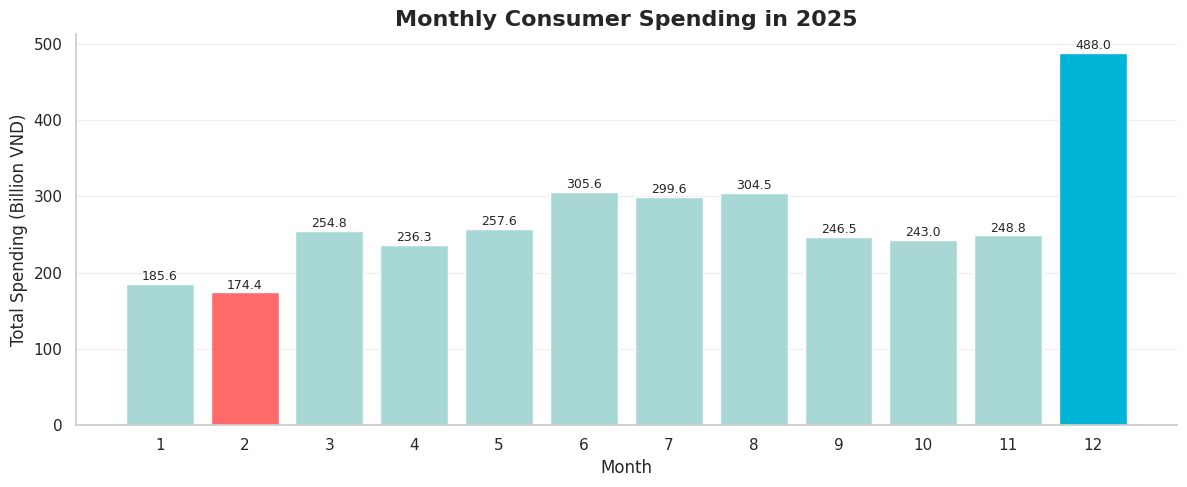

In [12]:
spending_bn = monthly["total_spend"] / 1e9
peak_month = int(peak["transaction_month"])
low_month = int(low["transaction_month"])

# Tô nổi tháng cao nhất (cyan) và thấp nhất (đỏ)
bar_colors = [
    CHART_CYAN if m == peak_month else CHART_RED if m == low_month else CHART_MINT
    for m in monthly["transaction_month"]
]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(monthly["transaction_month"], spending_bn, color=bar_colors, edgecolor="white")
ax.set_title("Monthly Consumer Spending in 2025", fontsize=16)
ax.set_xlabel("Month")
ax.set_ylabel("Total Spending (Billion VND)")
ax.set_xticks(range(1, 13))

label_offset = spending_bn.max() * 0.01
for bar, value in zip(bars, spending_bn):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + label_offset,
        f"{value:.1f}",
        ha="center",
        fontsize=9,
    )

fig.tight_layout()
save_chart(fig, "task1_q1_monthly_spending.png")
plt.show()

In [13]:
# Phân rã chênh lệch chi tiêu giữa tháng cao nhất và thấp nhất: số giao dịch x giá trị trung bình
spend_change = (peak["total_spend"] / low["total_spend"] - 1) * 100
count_change = (peak["transaction_count"] / low["transaction_count"] - 1) * 100
ticket_change = (peak["avg_ticket"] / low["avg_ticket"] - 1) * 100

header("Q1 - SPENDING DRIVER DECOMPOSITION")
print(f"Peak month: {peak_month} | Lowest month: {low_month}")
print(f"Spending growth: {spend_change:.2f}%")
print(f"Transaction count growth: {count_change:.2f}%")
print(f"Average ticket change: {ticket_change:.2f}%")

# (1 + count) x (1 + ticket) phải bằng (1 + spend)
print(
    "Validation:",
    round((1 + count_change / 100) * (1 + ticket_change / 100), 4),
    "vs",
    round(1 + spend_change / 100, 4),
)


=== Q1 - SPENDING DRIVER DECOMPOSITION ===
Peak month: 12 | Lowest month: 2
Spending growth: 179.89%
Transaction count growth: 187.33%
Average ticket change: -2.59%
Validation: 2.7989 vs 2.7989


### Q2 — Áp lực tài chính bóp méo cơ cấu chi tiêu

So sánh tỷ trọng chi tiêu thiết yếu / tùy ý giữa nhóm Stressed và nhóm Healthy.

In [14]:
sql_q2 = f"""
SELECT
    CASE
        WHEN financial_health_score < {HEALTH_STRESSED_THRESHOLD}
            THEN '1. Financially Stressed (<{HEALTH_STRESSED_THRESHOLD})'
        WHEN financial_health_score >= {HEALTH_HEALTHY_THRESHOLD}
            THEN '2. Healthy (>={HEALTH_HEALTHY_THRESHOLD})'
    END AS customer_segment,
    COUNT(consumer_id) AS total_months_recorded,
    SUM(total_spend_vnd) AS total_spend_vnd,
    SUM(essential_spend_vnd) AS essential_vnd,
    SUM(discretionary_spend_vnd) AS discretionary_vnd,
    ROUND(SUM(essential_spend_vnd) * 100.0 / SUM(total_spend_vnd), 2) AS essential_pct,
    ROUND(SUM(discretionary_spend_vnd) * 100.0 / SUM(total_spend_vnd), 2) AS discretionary_pct
FROM consumer_month
WHERE financial_health_score < {HEALTH_STRESSED_THRESHOLD}
   OR financial_health_score >= {HEALTH_HEALTHY_THRESHOLD}
GROUP BY customer_segment
ORDER BY customer_segment
"""
q2_table = run_sql(sql_q2)

display(
    q2_table.style.hide(axis="index").format({
        "total_spend_vnd": "{:,.0f}",
        "essential_vnd": "{:,.0f}",
        "discretionary_vnd": "{:,.0f}",
        "essential_pct": "{:.2f}",
        "discretionary_pct": "{:.2f}",
    })
)
save_table(q2_table, "task1_q2_spending_mix_by_health.csv")

customer_segment,total_months_recorded,total_spend_vnd,essential_vnd,discretionary_vnd,essential_pct,discretionary_pct
1. Financially Stressed (<40),95,"33,777,369,000","9,579,242,000","24,198,127,000",28.36,71.64
2. Healthy (>=80),475,"55,791,630,000","33,173,771,000","22,617,859,000",59.46,40.54


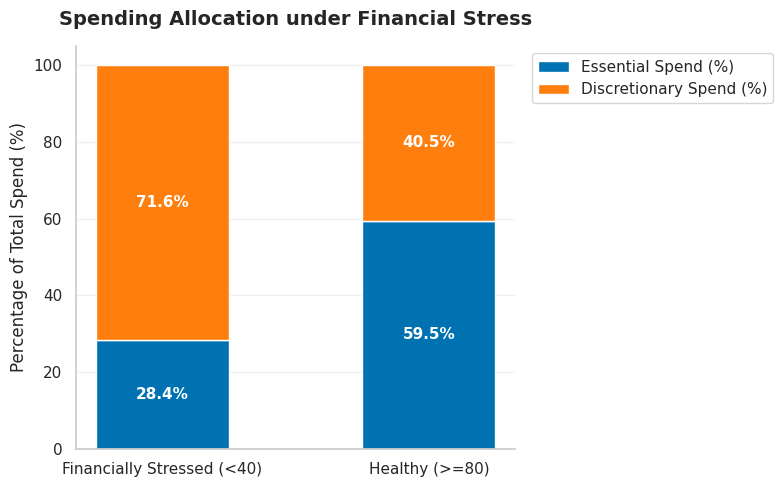

In [15]:
q2_labels = q2_table["customer_segment"].str.split(". ", n=1, regex=False).str[1].tolist()
essential_pct = (q2_table["essential_vnd"] / q2_table["total_spend_vnd"] * 100).to_numpy()
discretionary_pct = (q2_table["discretionary_vnd"] / q2_table["total_spend_vnd"] * 100).to_numpy()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(q2_labels, essential_pct, width=0.5, color=CHART_BLUE, label="Essential Spend (%)")
ax.bar(
    q2_labels, discretionary_pct, bottom=essential_pct, width=0.5,
    color=CHART_ORANGE, label="Discretionary Spend (%)",
)

for container in ax.containers:
    ax.bar_label(
        container, fmt="%.1f%%", label_type="center",
        color="white", fontweight="bold", fontsize=11,
    )

ax.set_title("Spending Allocation under Financial Stress", fontsize=14, pad=15)
ax.set_ylabel("Percentage of Total Spend (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))  # legend nằm ngoài khung biểu đồ

fig.tight_layout()
save_chart(fig, "task1_q2_spending_allocation.png")
plt.show()

**Key findings (Q2)**

- Nhóm Stressed dành **71.6%** chi tiêu cho Discretionary và chỉ **28.4%** cho Essential.
- Nhóm Healthy dành **59.5%** cho Essential và chỉ **40.5%** cho Discretionary.
- Kết luận: chi tiêu tùy ý quá mức là động lực chính của tình trạng căng thẳng tài chính trong tệp dữ liệu tổng hợp (synthetic) này.

### Q3 — Mức độ chấp nhận thanh toán số theo địa lý

In [16]:
header("TRANSACTION CHANNELS")
print(tx["transaction_channel"].value_counts(dropna=False))

header("ONLINE TRANSACTION FLAG")
print(tx["online_transaction_flag"].value_counts(dropna=False))

header("PROVINCES")
print("Total provinces:", tx["province_city"].nunique())

header("TRANSACTION AMOUNT")
print(tx["spend_amount_vnd"].describe())


=== TRANSACTION CHANNELS ===
transaction_channel
POS                  1089518
QR Payment            367682
E-commerce            161670
Mobile App            142399
Recurring Payment      91125
Name: count, dtype: int64

=== ONLINE TRANSACTION FLAG ===
online_transaction_flag
0    1457200
1     395194
Name: count, dtype: int64

=== PROVINCES ===
Total provinces: 34

=== TRANSACTION AMOUNT ===
count    1.852394e+06
mean     1.751589e+06
std      3.981350e+06
min      2.500000e+04
25%      2.410000e+05
50%      1.186000e+06
75%      2.077000e+06
max      7.237220e+08
Name: spend_amount_vnd, dtype: float64


In [17]:
# Giao dịch số = mọi kênh không phải POS
tx["is_digital"] = tx["transaction_channel"].isin(DIGITAL_CHANNELS).astype(int)
overall_digital = tx["is_digital"].mean() * 100

province = (
    tx.groupby("province_city")
    .agg(
        total_spend=("spend_amount_vnd", "sum"),
        transaction_count=("transaction_id", "count"),
        digital_count=("is_digital", "sum"),
    )
    .reset_index()
)
province["digital_share_pct"] = province["digital_count"] / province["transaction_count"] * 100
province["digital_gap_pp"] = province["digital_share_pct"] - overall_digital  # chênh lệch so với trung bình toàn quốc
province["spend_billion"] = province["total_spend"] / 1e9
province = province.sort_values("total_spend", ascending=False)

print(f"Overall digital share: {overall_digital:.2f}%")
display(
    province[
        ["province_city", "spend_billion", "transaction_count", "digital_share_pct", "digital_gap_pp"]
    ].head(15).round(2)
)
save_table(province, "task1_q3_province_digital_adoption.csv")

Overall digital share: 41.18%


,province_city,spend_billion,transaction_count,digital_share_pct,digital_gap_pp
24,Thành phố Hồ Chí Minh,442.18,250302,41.31,0.13
7,Hà Nội,267.26,149952,40.88,-0.31
32,Đồng Nai,183.07,106057,40.73,-0.46
33,Đồng Tháp,135.96,73161,41.86,0.68
18,Phú Thọ,135.94,79620,41.99,0.81
14,Lâm Đồng,135.39,75439,41.10,-0.08
4,Cần Thơ,126.03,68836,41.46,0.28
23,Thanh Hóa,122.66,67334,41.57,0.39
0,An Giang,120.60,70245,41.85,0.66
9,Hưng Yên,116.44,66638,40.78,-0.40


In [18]:
SELECTED_PROVINCES = ["Hà Nội", "Đồng Nai"]

national_channel = tx["transaction_channel"].value_counts(normalize=True) * 100
channel_breakdown = pd.crosstab(
    tx["province_city"], tx["transaction_channel"], normalize="index"
) * 100

result = channel_breakdown.loc[SELECTED_PROVINCES].copy()
result.loc["National Average"] = national_channel

display(result.round(2).T)
save_table(result.round(2).T, "task1_q3_channel_breakdown.csv", index=True)

province_city,Hà Nội,Đồng Nai,National Average
transaction_channel,,,
E-commerce,8.52,8.53,8.73
Mobile App,7.60,7.57,7.69
POS,59.12,59.27,58.82
QR Payment,19.87,19.85,19.85
Recurring Payment,4.88,4.78,4.92


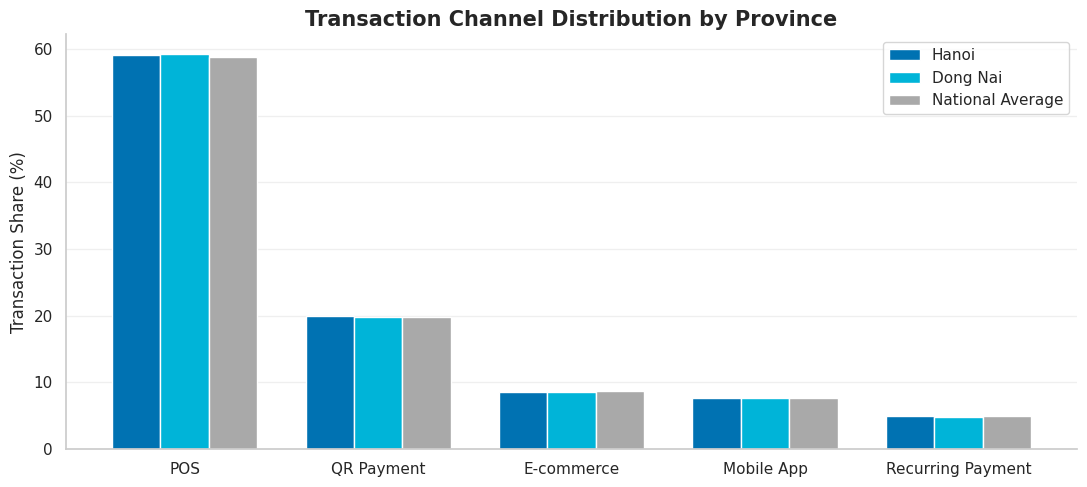

In [19]:
CHANNEL_ORDER = ["POS", "QR Payment", "E-commerce", "Mobile App", "Recurring Payment"]
bar_groups = [
    ("Hà Nội", "Hanoi", CHART_BLUE),
    ("Đồng Nai", "Dong Nai", CHART_CYAN),
    ("National Average", "National Average", CHART_GRAY),
]

x = np.arange(len(CHANNEL_ORDER))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 5))
for i, (key, label, color) in enumerate(bar_groups):
    ax.bar(x + (i - 1) * width, result.loc[key, CHANNEL_ORDER], width, label=label, color=color)

ax.set_ylabel("Transaction Share (%)")
ax.set_title("Transaction Channel Distribution by Province", fontsize=15)
ax.set_xticks(x)
ax.set_xticklabels(CHANNEL_ORDER)
ax.legend()

fig.tight_layout()
save_chart(fig, "task1_q3_channel_breakdown.png")
plt.show()

### Q4 — Ngành hàng: chi tiêu và tần suất

In [20]:
category = (
    tx.groupby("spending_category")
    .agg(
        total_spend=("spend_amount_vnd", "sum"),
        transaction_count=("transaction_id", "count"),
    )
    .reset_index()
)
category["avg_ticket"] = category["total_spend"] / category["transaction_count"]
category["spend_share_pct"] = category["total_spend"] / category["total_spend"].sum() * 100
category["transaction_share_pct"] = (
    category["transaction_count"] / category["transaction_count"].sum() * 100
)
category["spend_billion"] = category["total_spend"] / 1e9
category = category.sort_values("total_spend", ascending=False)

display(
    category[
        [
            "spending_category", "spend_billion", "transaction_count",
            "avg_ticket", "spend_share_pct", "transaction_share_pct",
        ]
    ].round(2)
)
print("\nTop category by spending:", category.loc[category["total_spend"].idxmax(), "spending_category"])
print("Top category by frequency:", category.loc[category["transaction_count"].idxmax(), "spending_category"])
save_table(category, "task1_q4_category_analysis.csv")

,spending_category,spend_billion,transaction_count,avg_ticket,spend_share_pct,transaction_share_pct
8,Siêu thị và tạp hóa tại cửa hàng,513.77,176191,2916003.35,15.83,9.51
6,Mua sắm tại cửa hàng,328.38,166463,1972668.30,10.12,8.99
5,Mua sắm trực tuyến,302.82,139322,2173547.67,9.33,7.52
12,Xăng dầu và di chuyển,298.39,188029,1586932.69,9.20,10.15
7,Nhà cửa và tiện ích,255.24,175460,1454705.48,7.87,9.47
10,Trẻ em và thú cưng,232.60,161727,1438195.57,7.17,8.73
3,Giải trí,215.07,134118,1603575.32,6.63,7.24
2,Dịch vụ trực tuyến khác,181.72,90654,2004533.38,5.60,4.89
4,Mua sắm khác tại cửa hàng,178.99,114229,1566911.27,5.52,6.17
13,Ăn uống,166.66,130729,1274851.39,5.14,7.06



Top category by spending: Siêu thị và tạp hóa tại cửa hàng
Top category by frequency: Xăng dầu và di chuyển


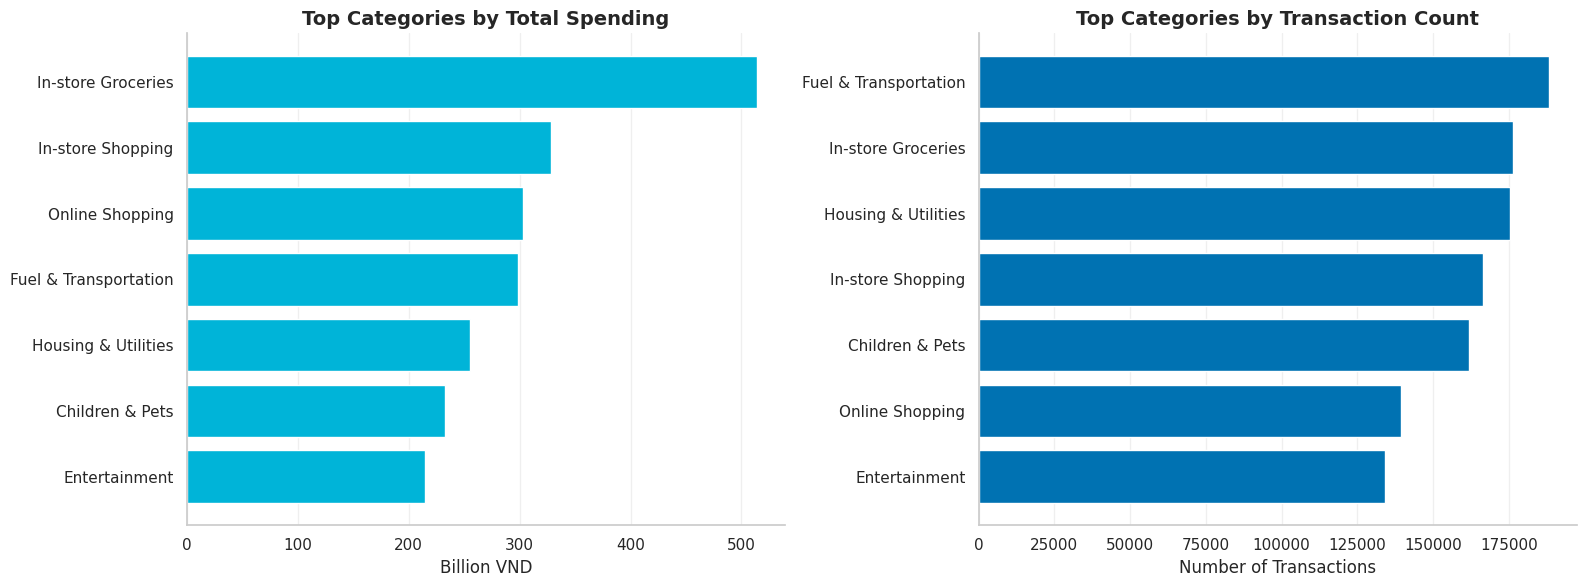

In [21]:
# Nhãn tiếng Anh cho biểu đồ
CATEGORY_LABELS_EN = {
    "Siêu thị và tạp hóa tại cửa hàng": "In-store Groceries",
    "Mua sắm tại cửa hàng": "In-store Shopping",
    "Mua sắm trực tuyến": "Online Shopping",
    "Xăng dầu và di chuyển": "Fuel & Transportation",
    "Nhà cửa và tiện ích": "Housing & Utilities",
    "Trẻ em và thú cưng": "Children & Pets",
    "Giải trí": "Entertainment",
    "Dịch vụ trực tuyến khác": "Other Online Services",
    "Mua sắm khác tại cửa hàng": "Other In-store Shopping",
    "Ăn uống": "Food & Dining",
    "Sức khỏe và thể thao": "Health & Fitness",
    "Du lịch": "Travel",
    "Chăm sóc cá nhân": "Personal Care",
    "Tạp hóa trực tuyến": "Online Groceries",
}
category["category_en"] = category["spending_category"].map(CATEGORY_LABELS_EN)

top_spend = category.nlargest(7, "total_spend")
top_count = category.nlargest(7, "transaction_count")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].barh(top_spend["category_en"][::-1], top_spend["spend_billion"][::-1], color=CHART_CYAN)
axes[0].set_title("Top Categories by Total Spending")
axes[0].set_xlabel("Billion VND")

axes[1].barh(top_count["category_en"][::-1], top_count["transaction_count"][::-1], color=CHART_BLUE)
axes[1].set_title("Top Categories by Transaction Count")
axes[1].set_xlabel("Number of Transactions")

for ax in axes:
    ax.grid(axis="x", alpha=0.3)
    ax.grid(axis="y", visible=False)

fig.tight_layout()
save_chart(fig, "task1_q4_category_comparison.png")
plt.show()

### Q5 — Nhóm tuổi giao dịch nhiều nhưng điểm sức khỏe thấp

In [22]:
sql_q5 = """
SELECT
    CASE
        WHEN age < 25 THEN '1. <25 (Gen Z)'
        WHEN age BETWEEN 25 AND 34 THEN '2. 25-34 (Young Professionals)'
        WHEN age BETWEEN 35 AND 49 THEN '3. 35-49 (Prime Working)'
        WHEN age BETWEEN 50 AND 64 THEN '4. 50-64 (Mature Working)'
        ELSE '5. >=65 (Senior)'
    END AS age_cohort,
    COUNT(DISTINCT consumer_id) AS total_customers,
    COUNT(*) AS total_months_recorded,
    ROUND(AVG(transaction_count), 1) AS avg_tx_count,
    ROUND(AVG(active_transaction_days), 1) AS avg_active_days,
    ROUND(AVG(financial_health_score), 2) AS avg_health_score,
    ROUND(AVG(essential_spend_ratio) * 100, 2) AS avg_essential_ratio_pct,
    ROUND(AVG(spend_to_income_ratio) * 100, 2) AS avg_spend_to_income_pct,
    ROUND(AVG(credit_utilization_ratio) * 100, 2) AS avg_credit_utilization_pct
FROM consumer_month
GROUP BY age_cohort
ORDER BY age_cohort
"""
q5_summary = run_sql(sql_q5)

display(q5_summary)
save_table(q5_summary, "task1_q5_age_cohort_summary.csv")

,age_cohort,total_customers,total_months_recorded,avg_tx_count,avg_active_days,avg_health_score,avg_essential_ratio_pct,avg_spend_to_income_pct,avg_credit_utilization_pct
0,1. <25 (Gen Z),69,631,221.6,28.4,65.94,35.49,67.60,17.27
1,2. 25-34 (Young Professionals),177,2124,178.7,28.9,65.79,46.75,71.58,19.49
2,3. 35-49 (Prime Working),261,3132,203.0,29.3,66.38,46.96,69.34,19.12
3,4. 50-64 (Mature Working),277,2888,134.5,28.0,66.50,50.82,71.02,19.49
4,5. >=65 (Senior),215,2217,139.1,28.2,66.86,50.92,68.53,19.13


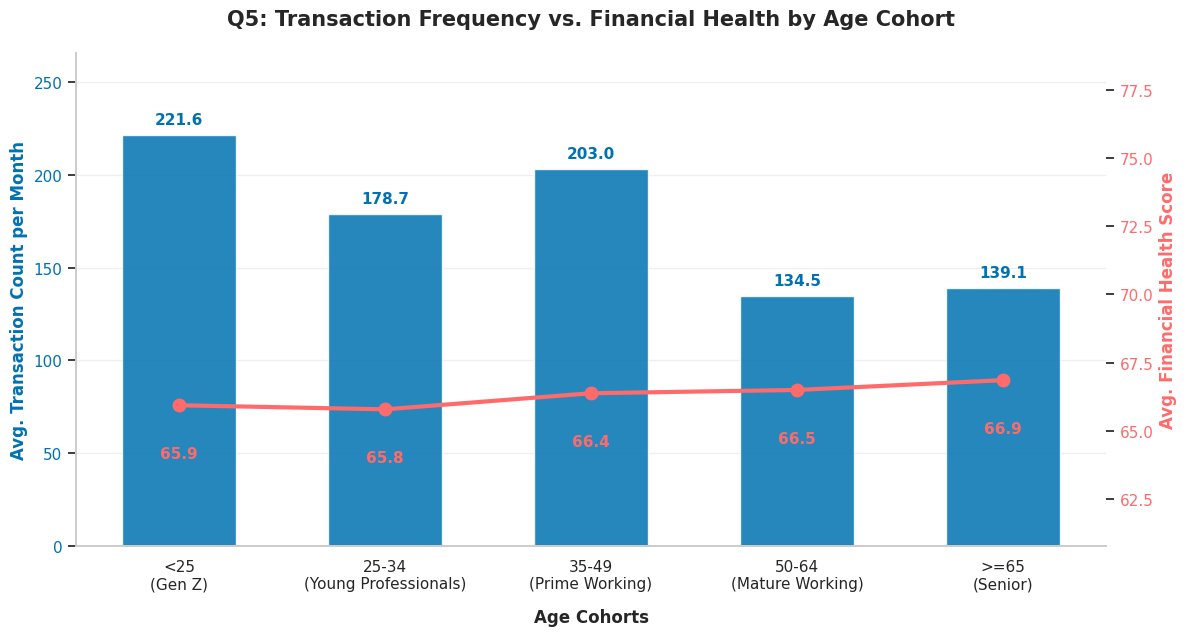

In [23]:
# Cột: số giao dịch trung bình (trục trái). Đường: điểm sức khỏe trung bình (trục phải)
x = np.arange(len(q5_summary))
tick_labels = [
    label.split(". ", 1)[1].replace(" (", "\n(") for label in q5_summary["age_cohort"]
]
tx_max = q5_summary["avg_tx_count"].max()

fig, ax1 = plt.subplots(figsize=(12, 6.5))
bars = ax1.bar(
    x, q5_summary["avg_tx_count"], width=0.55, color=CHART_BLUE, alpha=0.85,
    label="Avg. Monthly Transaction Count",
)
ax1.set_ylabel("Avg. Transaction Count per Month", color=CHART_BLUE, fontweight="bold", fontsize=12)
ax1.tick_params(axis="y", labelcolor=CHART_BLUE)
ax1.set_xlabel("Age Cohorts", fontweight="bold", fontsize=12, labelpad=12)
ax1.set_xticks(x)
ax1.set_xticklabels(tick_labels, fontsize=11)
ax1.set_ylim(0, tx_max * 1.2)  # chừa 20% phía trên để nhãn số không đè lên đường

for bar in bars:
    height = bar.get_height()
    ax1.text(
        bar.get_x() + bar.get_width() / 2, height + tx_max * 0.02, f"{height:.1f}",
        ha="center", va="bottom", color=CHART_BLUE, fontweight="bold", fontsize=11,
    )

ax2 = ax1.twinx()
ax2.plot(
    x, q5_summary["avg_health_score"], color=CHART_RED, marker="o",
    linewidth=3, markersize=9, label="Avg. Financial Health Score",
)
ax2.set_ylabel("Avg. Financial Health Score", color=CHART_RED, fontweight="bold", fontsize=12)
ax2.tick_params(axis="y", labelcolor=CHART_RED)
ax2.grid(False)
ax2.set_ylim(q5_summary["avg_health_score"].min() - 5, q5_summary["avg_health_score"].max() + 12)

# Nhãn điểm sức khỏe đặt dưới điểm nút để không chồng lên nhãn của cột
for xi, score in zip(x, q5_summary["avg_health_score"]):
    ax2.annotate(
        f"{score:.1f}", (xi, score - 1.5), ha="center", va="top",
        color=CHART_RED, fontweight="bold", fontsize=11,
    )

ax1.set_title("Q5: Transaction Frequency vs. Financial Health by Age Cohort", fontsize=15, pad=20)
fig.tight_layout()
save_chart(fig, "task1_q5_age_cohort.png")
plt.show()

**Key findings (Q5)**

- **Nhóm dễ tổn thương nhất:** nhóm **25–34 (Young Professionals)** có điểm sức khỏe tài chính trung bình thấp nhất (**65.79**), dù vẫn giao dịch năng động với **178.7 giao dịch/tháng**.
- **Giao dịch dày nhưng điểm thấp:** nhóm **<25 (Gen Z)** giao dịch nhiều nhất (**221.6 giao dịch/tháng**) và điểm sức khỏe cũng xấp xỉ mức đáy (**65.94**).
- **Nguyên nhân chính:**
  - *Áp lực chi tiêu so với thu nhập:* nhóm 25–34 có tỷ lệ chi tiêu / thu nhập cao nhất (**71.58%**), biên an toàn tài chính bị thu hẹp.
  - *Bẫy chi tiêu tùy ý:* nhóm Gen Z có tỷ trọng chi tiêu thiết yếu thấp kỷ lục (**35.49%**), tức gần **65% ngân sách dành cho chi tiêu tùy ý**, nền tài chính rất mỏng trước các cú sốc dòng tiền.
- **Hàm ý kinh doanh (không mang tính trừng phạt):** khách hàng trẻ là động lực tăng trưởng giao dịch, nên hỗ trợ bằng **Smart Spend Alerts** và **Budgeting Tools** thay vì thắt chặt hạn mức tín dụng.

## Task 2 — Financial health analysis

### 2.1 Phân phối sức khỏe tài chính

In [24]:
sql_t21 = f"""
SELECT
    CASE
        WHEN financial_health_score >= {HEALTH_HEALTHY_THRESHOLD}
            THEN '1. Healthy (>={HEALTH_HEALTHY_THRESHOLD})'
        WHEN financial_health_score >= {HEALTH_STABLE_THRESHOLD}
            THEN '2. Stable ({HEALTH_STABLE_THRESHOLD}-{HEALTH_HEALTHY_THRESHOLD - 1})'
        WHEN financial_health_score >= {HEALTH_STRESSED_THRESHOLD}
            THEN '3. At-Risk ({HEALTH_STRESSED_THRESHOLD}-{HEALTH_STABLE_THRESHOLD - 1})'
        ELSE '4. Financially Stressed (<{HEALTH_STRESSED_THRESHOLD})'
    END AS health_segment,
    COUNT(*) AS total_records,
    ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM consumer_month), 2) AS percentage
FROM consumer_month
GROUP BY health_segment
ORDER BY health_segment
"""
segment_dist = run_sql(sql_t21)

display(segment_dist)
save_table(segment_dist, "task2_1_health_segments.csv")

,health_segment,total_records,percentage
0,1. Healthy (>=80),475,4.32
1,2. Stable (60-79),7965,72.46
2,3. At-Risk (40-59),2457,22.35
3,4. Financially Stressed (<40),95,0.86


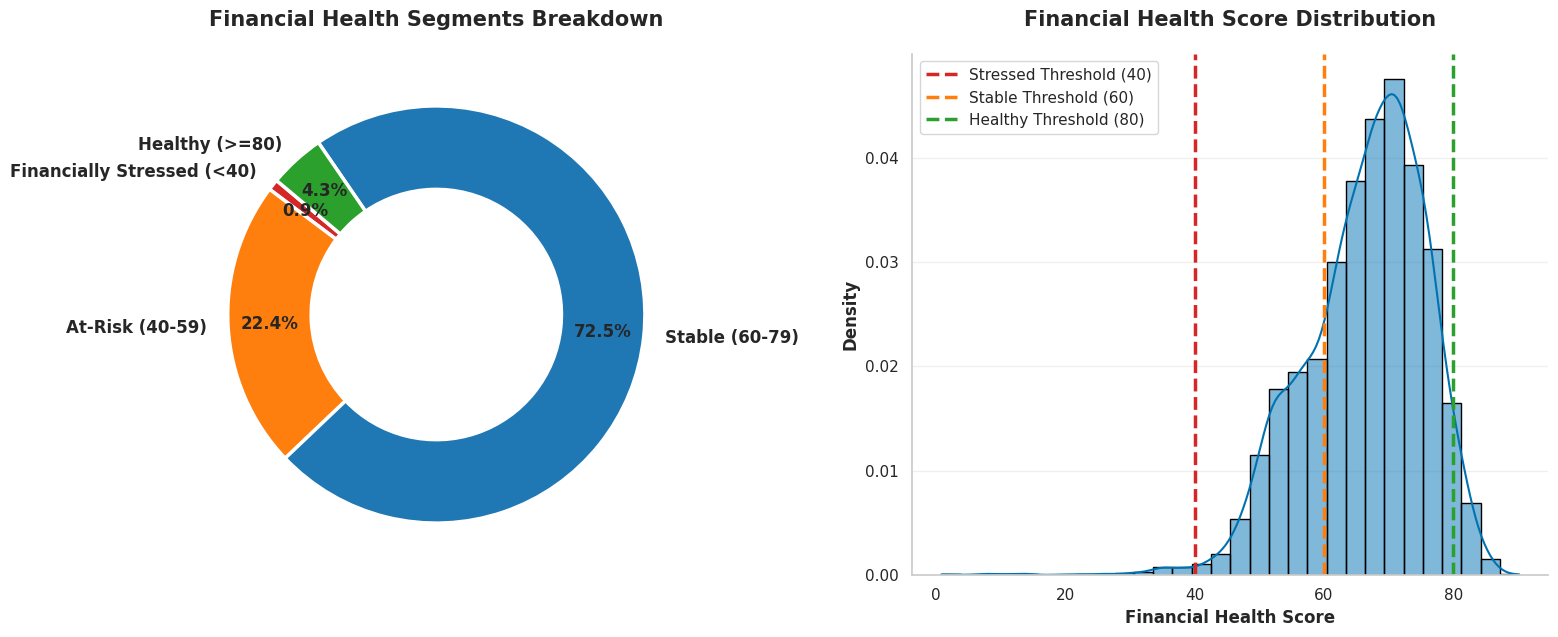

In [25]:
# Xếp theo mức rủi ro giảm dần (Stressed -> At-Risk -> Stable -> Healthy) để khớp thứ tự HEALTH_COLORS
segment_plot = segment_dist.sort_values("health_segment", ascending=False)
segment_labels = segment_plot["health_segment"].str.split(". ", n=1, regex=False).str[1].tolist()

fig, (ax_donut, ax_hist) = plt.subplots(1, 2, figsize=(16, 6.5))

# Donut: tỷ trọng từng phân khúc
ax_donut.pie(
    segment_plot["percentage"],
    labels=segment_labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=list(HEALTH_COLORS.values()),
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2.5),
    textprops=dict(fontsize=12, fontweight="bold"),
    pctdistance=0.8,
    labeldistance=1.1,
)
ax_donut.set_title("Financial Health Segments Breakdown", fontsize=15, pad=20)

# Histogram + KDE, kèm các vạch ngưỡng cùng màu với donut
sns.histplot(
    cm["financial_health_score"], bins=30, kde=True, stat="density",
    color=CHART_BLUE, edgecolor="black", ax=ax_hist,
)
ax_hist.set_title("Financial Health Score Distribution", fontsize=15, pad=20)
ax_hist.set_xlabel("Financial Health Score", fontweight="bold", fontsize=12)
ax_hist.set_ylabel("Density", fontweight="bold", fontsize=12)

thresholds = [
    (HEALTH_STRESSED_THRESHOLD, "Stressed", "Stressed"),
    (HEALTH_STABLE_THRESHOLD, "At-Risk", "Stable"),
    (HEALTH_HEALTHY_THRESHOLD, "Healthy", "Healthy"),
]
for value, color_key, name in thresholds:
    ax_hist.axvline(
        value, color=HEALTH_COLORS[color_key], linestyle="--", linewidth=2.5,
        label=f"{name} Threshold ({value})",
    )
ax_hist.legend(loc="upper left", frameon=True, fontsize=11)

fig.tight_layout()
save_chart(fig, "task2_1_health_segments.png")
plt.show()

**Key findings (2.1)**

- **Đa số ở mức Stable:** phân phối điểm sức khỏe lệch trái rõ rệt, phần lớn khách hàng (**72.46%**) nằm trong vùng **Stable (60-79)**. Chất lượng tín dụng chung của tệp dữ liệu ITB ở mức tốt, rủi ro vỡ nợ hệ thống thấp.
- **Thiếu nhóm Healthy:** chỉ **4.32%** khách hàng đạt **Healthy (>=80)**. ITB chưa khai thác hết tiềm năng bán chéo các sản phẩm tài sản sinh lời (tiết kiệm, đầu tư) cho tệp Stable để nâng hạng họ lên Healthy.
- **Đuôi cảnh báo (At-Risk và Stressed):**
  - Nhóm **Financially Stressed (<40)** rất nhỏ (**0.86%**), chưa gây rủi ro nợ xấu nghiêm trọng ngay lập tức.
  - Tuy nhiên có tới **22.35%** khách hàng ở mức **At-Risk (40-59)**. Nếu gặp cú sốc kinh tế (mất việc, lạm phát), tệp này rất dễ trượt xuống ngưỡng Stressed.
- **Hàm ý chiến lược:** trọng tâm không phải thu hồi nợ (nhóm Stressed rất nhỏ) mà là **phòng ngừa rủi ro cho nhóm At-Risk** và **nâng hạng tài sản cho nhóm Stable**.

### 2.2 Phân tích tương quan

In [26]:
factors = [
    "financial_health_score",
    "credit_utilization_ratio",
    "spend_to_income_ratio",
    "spending_volatility",
    "essential_spend_ratio",
    "discretionary_spend_ratio",
    "online_spend_ratio",
    "transaction_count",
]

# Hệ số tương quan Pearson của từng chỉ số hành vi với điểm sức khỏe
health_corr = (
    cm[factors].corr()["financial_health_score"]
    .drop("financial_health_score")
    .sort_values()
)
health_corr_table = health_corr.to_frame(name="correlation_coefficient")

display(health_corr_table)
save_table(health_corr_table, "task2_2_health_correlation.csv", index=True)

,correlation_coefficient
spend_to_income_ratio,-0.898049
credit_utilization_ratio,-0.862251
spending_volatility,-0.496167
discretionary_spend_ratio,-0.480580
online_spend_ratio,-0.273146
transaction_count,-0.253050
essential_spend_ratio,0.480580


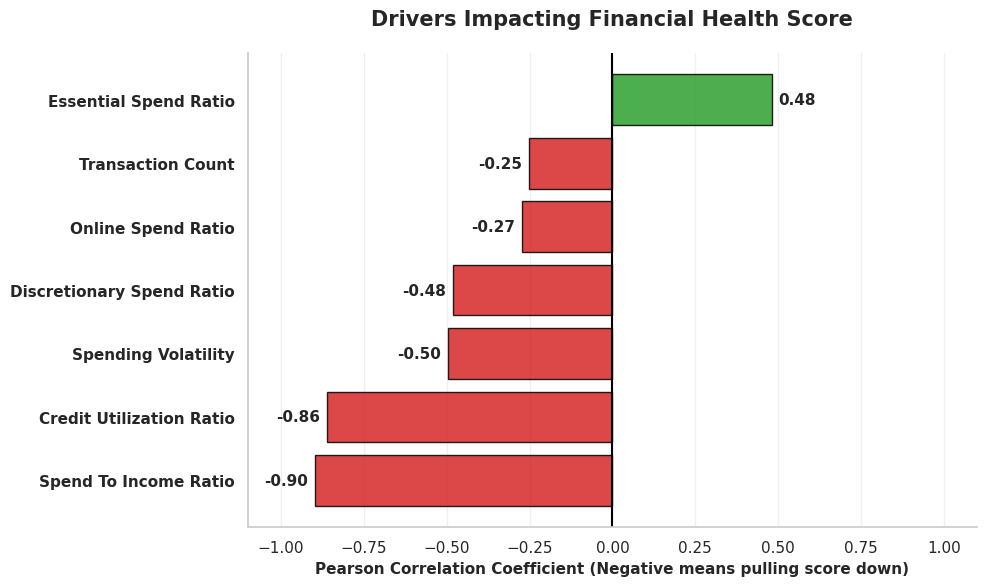

In [27]:
# Đỏ: tương quan âm (kéo điểm xuống). Xanh lá: tương quan dương
bar_colors = [
    HEALTH_COLORS["Stressed"] if value < 0 else HEALTH_COLORS["Healthy"]
    for value in health_corr
]
factor_labels = [name.replace("_", " ").title() for name in health_corr.index]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(range(len(health_corr)), health_corr.values, color=bar_colors, alpha=0.85, edgecolor="black")
ax.set_yticks(range(len(factor_labels)))
ax.set_yticklabels(factor_labels, fontsize=11, fontweight="bold")

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + (0.02 if width > 0 else -0.02),
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center",
        ha="left" if width > 0 else "right",
        fontweight="bold",
        fontsize=11,
    )

ax.axvline(x=0, color="black", linewidth=1.5)
ax.set_xlim(-1.1, 1.1)  # chừa chỗ cho nhãn số ở hai đầu
ax.set_title("Drivers Impacting Financial Health Score", fontsize=15, pad=20)
ax.set_xlabel("Pearson Correlation Coefficient (Negative means pulling score down)", fontweight="bold", fontsize=11)
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)

fig.tight_layout()
save_chart(fig, "task2_2_health_drivers.png")
plt.show()

**Key findings (2.2)**

- **Hai yếu tố kéo điểm mạnh nhất (tương quan âm mạnh):** **Spend To Income Ratio (r = -0.90)** và **Credit Utilization Ratio (r = -0.86)**. Khi khách hàng chi tiêu vượt thu nhập và dùng gần hết hạn mức thẻ tín dụng, điểm sức khỏe giảm rất nhanh. Đây là hai tín hiệu "đèn đỏ" sớm nhất về rủi ro vỡ nợ.
- **Các yếu tố thúc đẩy suy giảm (tương quan âm vừa):** **Spending Volatility (r = -0.50)** và **Discretionary Spend Ratio (r = -0.48)**. Khách hàng chi tiêu bốc đồng, thiếu kế hoạch ngân sách thường có nền tài chính mong manh hơn.
- **Lá chắn bảo vệ (tương quan dương):** **Essential Spend Ratio (r = +0.48)** là yếu tố duy nhất có tương quan dương. Ưu tiên chi cho nhu cầu thiết yếu giúp giữ nền tài chính ổn định.
- **Hàm ý chiến lược:** cài **cảnh báo ngưỡng đòn bẩy (Utilization Alerts)** trên Mobile App. Khi `spend_to_income_ratio` chạm 50% hoặc `credit_utilization` vượt 30%, app tự đẩy thông báo đề xuất gói vay trả góp (Installment Loans) để giảm áp lực thanh toán cuối kỳ, thay vì khóa thẻ cứng nhắc.

### 2.3 Khác biệt nhân khẩu học

Lấy điểm sức khỏe của 5 nghề nghiệp và 5 tỉnh/thành có nhiều bản ghi nhất, so sánh phân phối bằng boxplot.


=== HEALTH SCORE BY TOP 5 OCCUPATIONS ===


,occupation,count,mean,median,min,max
0,Chuyên viên dựng phim,109,64.9,64.8,46.3,79.2
1,Chuyên viên trắc địa,108,64.8,66.4,26.5,86.6
2,Kỹ sư sản xuất,84,71.9,74.2,48.1,82.4
3,Kỹ sư vật liệu,84,71.1,72.6,50.4,86.9
4,Nhà khoa học thính học,120,71.2,72.3,41.3,85.7



=== HEALTH SCORE BY TOP 5 PROVINCES/CITIES ===


,province_city,count,mean,median,min,max
0,Cần Thơ,496,66.9,68.0,14.4,85.9
1,Hà Nội,873,68.0,69.6,0.8,89.1
2,Lâm Đồng,425,64.9,66.5,3.6,85.0
3,Thành phố Hồ Chí Minh,1467,67.9,69.0,25.7,90.2
4,Đồng Nai,556,66.2,67.2,34.8,86.9


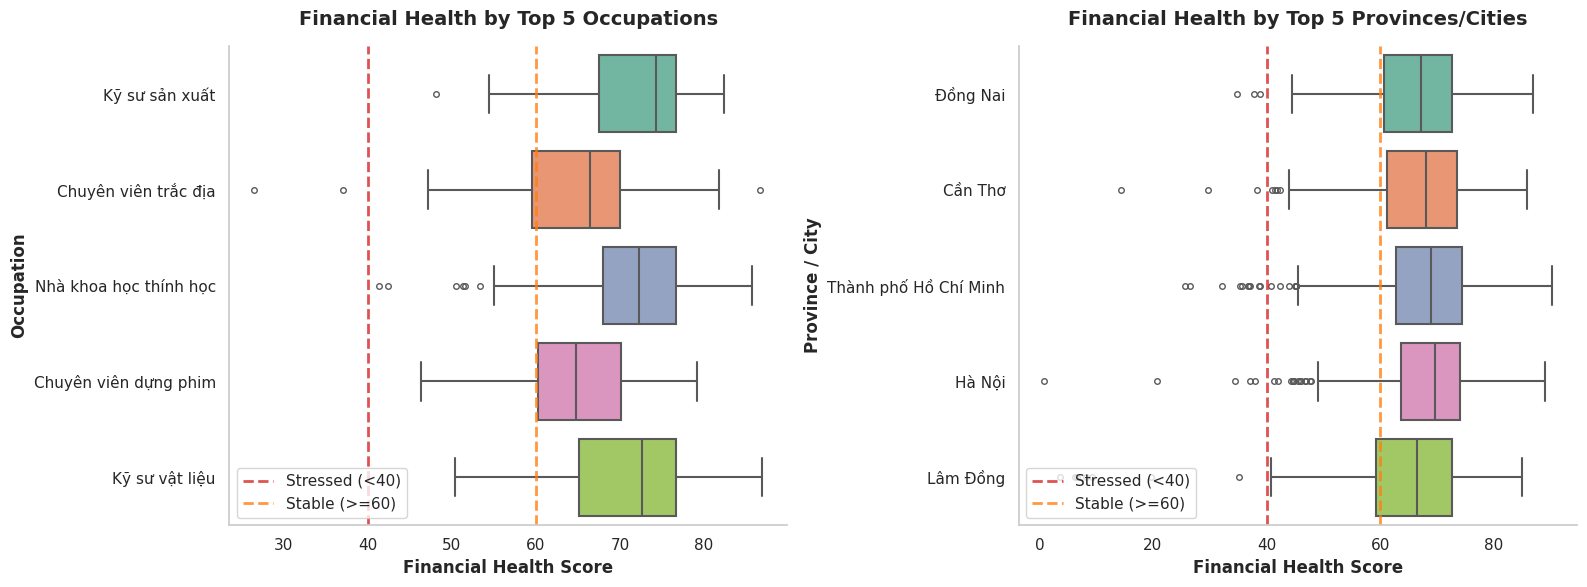

In [28]:
def top_group_scores(column, top_n=5):
    """Lấy điểm sức khỏe tài chính của top_n nhóm đông bản ghi nhất theo `column`."""
    sql = f"""
    SELECT {column}, financial_health_score
    FROM consumer_month
    WHERE {column} IN (
        SELECT {column}
        FROM consumer_month
        GROUP BY {column}
        ORDER BY COUNT(*) DESC
        LIMIT {top_n}
    )
    """
    return run_sql(sql)


demographic_views = [
    # (cột nhân khẩu học, nhãn trục, tiêu đề, tên file bảng)
    ("occupation", "Occupation", "Top 5 Occupations", "task2_3_health_by_occupation.csv"),
    ("province_city", "Province / City", "Top 5 Provinces/Cities", "task2_3_health_by_province.csv"),
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (column, axis_label, title, table_name) in zip(axes, demographic_views):
    scores = top_group_scores(column)

    group_stats = (
        scores.groupby(column)["financial_health_score"]
        .agg(count="count", mean="mean", median="median", min="min", max="max")
        .round(1)
        .reset_index()
    )
    header(f"HEALTH SCORE BY {title.upper()}")
    display(group_stats)
    save_table(group_stats, table_name)

    sns.boxplot(
        x="financial_health_score", y=column, data=scores, ax=ax,
        hue=column, legend=False, palette="Set2", linewidth=1.5, fliersize=4,
    )
    ax.set_title(f"Financial Health by {title}", fontsize=14, pad=15)
    ax.set_xlabel("Financial Health Score", fontweight="bold")
    ax.set_ylabel(axis_label, fontweight="bold")
    ax.axvline(HEALTH_STRESSED_THRESHOLD, color=HEALTH_COLORS["Stressed"], linestyle="--", linewidth=2, alpha=0.8,
               label=f"Stressed (<{HEALTH_STRESSED_THRESHOLD})")
    ax.axvline(HEALTH_STABLE_THRESHOLD, color=HEALTH_COLORS["At-Risk"], linestyle="--", linewidth=2, alpha=0.8,
               label=f"Stable (>={HEALTH_STABLE_THRESHOLD})")
    ax.legend(loc="lower left")

fig.tight_layout()
save_chart(fig, "task2_3_demographics.png")
plt.show()

**Key findings (2.3)**

- **Phân hóa theo nghề nghiệp:**
  - Nhóm ngành Kỹ thuật (Kỹ sư sản xuất, Kỹ sư vật liệu) có nền tài chính vững nhất, điểm trung vị trên 72 và phần lớn hộp phân bố nằm trong vùng Stable.
  - Nhóm Chuyên viên trắc địa phân tán rủi ro lớn nhất, có các điểm ngoại lai (outliers) rớt sâu qua vạch đỏ xuống vùng Stressed (<40).
- **Rủi ro ngầm tại đô thị lớn:**
  - Xét điểm trung vị, 5 tỉnh/thành khá đồng đều và đều nằm trên mốc 60 (Stable).
  - Hà Nội và TP.HCM lại có chuỗi điểm ngoại lai dày nhất dưới mốc 40. Một số khách hàng tại Hà Nội và Lâm Đồng chạm đáy gần 0, cho thấy rủi ro đứt gãy dòng tiền rất nghiêm trọng.
- **Hàm ý chiến lược:** không nên chỉ dựa vào điểm trung bình để duyệt hạn mức tín dụng. Cần **mô hình chấm điểm rủi ro đa chiều**: khách làm nghề biến động cao (như Trắc địa) và sống ở khu vực chi phí lớn (Hà Nội/TP.HCM) nên được điều chỉnh hạn mức thấu chi hoặc bật Budgeting Alerts chặt hơn.

### 2.4 Nhóm "Stressed but Highly Engaged"

Nhóm giao thoa có điểm sức khỏe < 40 nhưng engagement ≥ 75.

In [29]:
sql_t24 = f"""
SELECT
    CASE
        WHEN financial_health_score < {HEALTH_STRESSED_THRESHOLD}
         AND engagement_score >= {ENGAGEMENT_HIGH_THRESHOLD}
            THEN 'Target: Stressed & Highly Engaged'
        ELSE 'Others'
    END AS segment,
    COUNT(DISTINCT consumer_id) AS total_customers,
    ROUND(COUNT(DISTINCT consumer_id) * 100.0
          / (SELECT COUNT(DISTINCT consumer_id) FROM consumer_month), 2) AS pct_customers,
    ROUND(AVG(transaction_count), 1) AS avg_monthly_tx,
    ROUND(AVG(spend_to_income_ratio) * 100, 1) AS avg_spend_income_pct
FROM consumer_month
GROUP BY segment
ORDER BY segment
"""
stressed_engaged_profile = run_sql(sql_t24)

display(stressed_engaged_profile)
save_table(stressed_engaged_profile, "task2_4_stressed_highly_engaged.csv")

,segment,total_customers,pct_customers,avg_monthly_tx,avg_spend_income_pct
0,Others,999,100.00,168.8,69.1
1,Target: Stressed & Highly Engaged,59,5.91,131.0,199.0


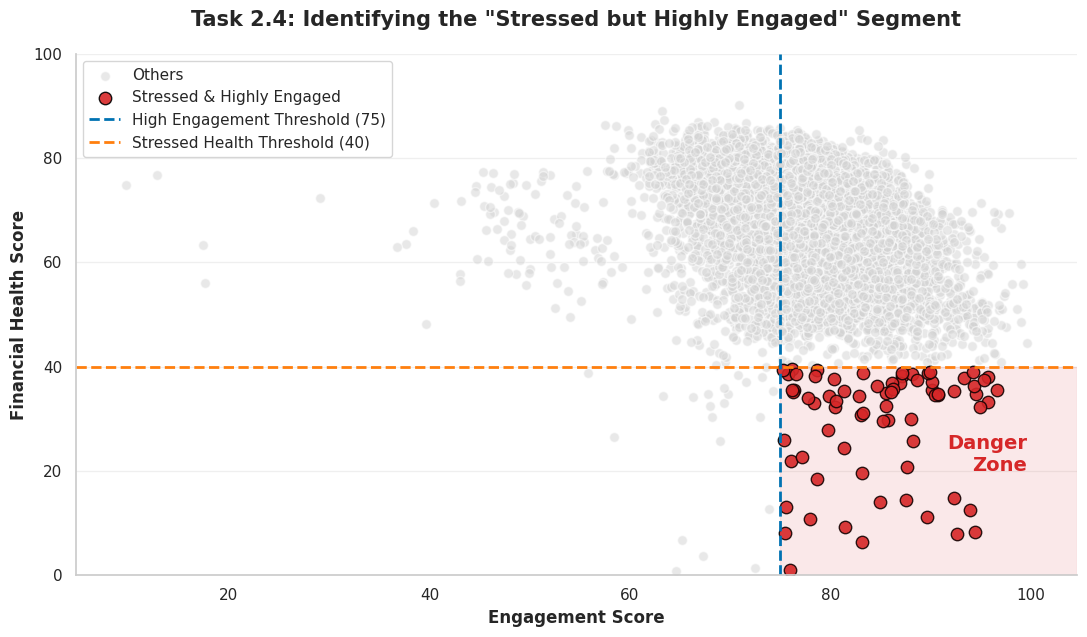

In [30]:
target_group = cm[cm["stressed_high_eng"]]
others = cm[~cm["stressed_high_eng"]]
engagement_top = cm["engagement_score"].max()

fig, ax = plt.subplots(figsize=(11, 6.5))

# Nhóm khác làm nền (xám nhạt), nhóm mục tiêu nổi bật (đỏ)
ax.scatter(
    others["engagement_score"], others["financial_health_score"],
    color="lightgrey", alpha=0.5, edgecolor="white", s=50, label="Others",
)
ax.scatter(
    target_group["engagement_score"], target_group["financial_health_score"],
    color=HEALTH_COLORS["Stressed"], alpha=0.9, edgecolor="black", s=80,
    label="Stressed & Highly Engaged",
)

# Hai vạch ngưỡng và vùng "Danger Zone" (góc dưới bên phải)
ax.axvline(ENGAGEMENT_HIGH_THRESHOLD, color=CHART_BLUE, linestyle="--", linewidth=2,
           label=f"High Engagement Threshold ({ENGAGEMENT_HIGH_THRESHOLD})")
ax.axhline(HEALTH_STRESSED_THRESHOLD, color=CHART_ORANGE, linestyle="--", linewidth=2,
           label=f"Stressed Health Threshold ({HEALTH_STRESSED_THRESHOLD})")
ax.axvspan(
    ENGAGEMENT_HIGH_THRESHOLD, engagement_top + 5,
    ymin=0, ymax=HEALTH_STRESSED_THRESHOLD / 100,  # ymax tính theo tỷ lệ trục, trục y cố định 0-100
    color=HEALTH_COLORS["Stressed"], alpha=0.1,
)
ax.text(
    engagement_top, HEALTH_STRESSED_THRESHOLD / 2, "Danger\nZone",
    color=HEALTH_COLORS["Stressed"], fontweight="bold", fontsize=14, ha="right",
)

ax.set_title('Task 2.4: Identifying the "Stressed but Highly Engaged" Segment', fontsize=15, pad=20)
ax.set_xlabel("Engagement Score", fontweight="bold", fontsize=12)
ax.set_ylabel("Financial Health Score", fontweight="bold", fontsize=12)
ax.set_xlim(cm["engagement_score"].min() - 5, engagement_top + 5)
ax.set_ylim(0, 100)
ax.legend(loc="upper left")

fig.tight_layout()
save_chart(fig, "task2_4_stressed_highly_engaged.png")
plt.show()

**Key findings (2.4)**

- **Quy mô vùng nguy hiểm (Danger Zone):** **59 khách hàng** (**5.91%** tệp khách hàng) nằm ở góc rủi ro nhất: điểm sức khỏe < 40 nhưng engagement $\ge$ 75.
- **Nghịch lý hành vi:** nhóm này chi tiêu gần gấp đôi thu nhập (**Avg_Spend_Income_Pct chạm 199%**) nhưng vẫn giao dịch rất dày (**131 giao dịch/tháng**). Họ đang dùng đòn bẩy tín dụng xoay vòng (thẻ tín dụng, thấu chi) đến mức cạn kiệt để duy trì nhịp tiêu dùng.
- **Hàm ý kinh doanh:** đây là những "quả bom nổ chậm" về nợ xấu, nhưng lại gắn kết (stickiness) rất chặt với hệ sinh thái của ITB.
  - *Giải pháp can thiệp:* không khóa thẻ đột ngột (dễ kích hoạt vỡ nợ tức thì), mà tự động nhận diện và đề xuất chuyển dư nợ hiện tại thành **khoản vay trả góp (Installment Loans)** để kéo giãn áp lực thanh toán, kết hợp bật **Discretionary Spend Lock** trên Mobile App.

## Task 3 — Engagement analysis

### 3.1 Phân phối engagement score và tỷ trọng từng nhóm


=== ENGAGEMENT SCORE DISTRIBUTION ===


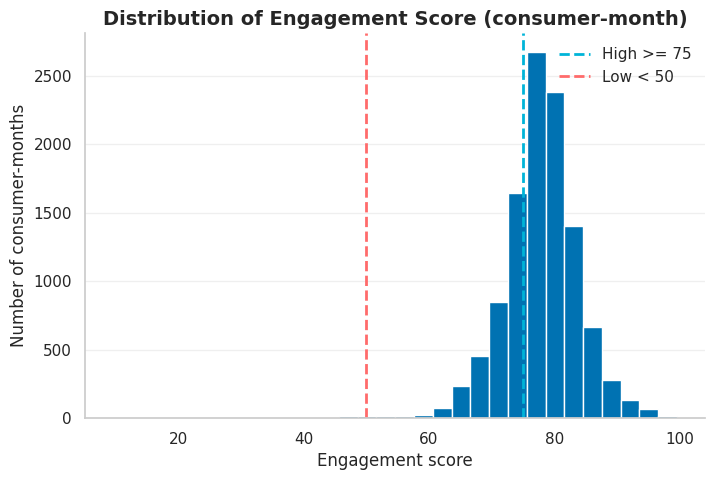

In [31]:
summary = {}  # gom các con số chính của Task 3 để xuất ở mục 3.6 và đối chiếu ở mục 3.7

header("ENGAGEMENT SCORE DISTRIBUTION")

fig, ax = plt.subplots()
ax.hist(cm["engagement_score"], bins=30, color=CHART_BLUE, edgecolor="white")
ax.axvline(ENGAGEMENT_HIGH_THRESHOLD, color=CHART_CYAN, linestyle="--", linewidth=2,
           label=f"High >= {ENGAGEMENT_HIGH_THRESHOLD}")
ax.axvline(ENGAGEMENT_LOW_THRESHOLD, color=CHART_RED, linestyle="--", linewidth=2,
           label=f"Low < {ENGAGEMENT_LOW_THRESHOLD}")
ax.set_title("Distribution of Engagement Score (consumer-month)")
ax.set_xlabel("Engagement score")
ax.set_ylabel("Number of consumer-months")
ax.legend(frameon=False)

save_chart(fig, "task3_engagement_distribution_hist.png")
plt.show()

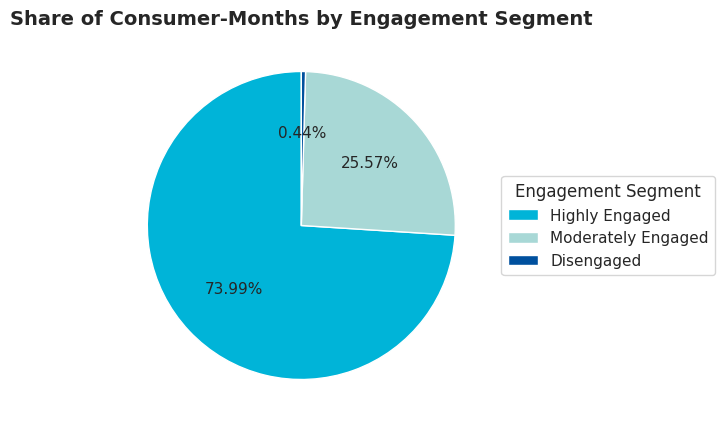

Total consumer-months: 10,992
  Highly Engaged: n = 8,133 (73.99%)
  Moderately Engaged: n = 2,811 (25.57%)
  Disengaged: n = 48 (0.44%)


In [32]:
seg_counts = cm["engagement_band"].value_counts()
seg_pct = (seg_counts / n_consumer_months * 100).round(2)

bands_desc = ENGAGEMENT_BANDS[::-1]  # Highly -> Moderately -> Disengaged
fig, ax = plt.subplots()
wedges, texts, autotexts = ax.pie(
    [seg_pct.get(band, 0) for band in bands_desc],
    colors=[ENGAGEMENT_COLORS[band] for band in bands_desc],
    autopct="%1.2f%%",
    startangle=90,
)
ax.set_title("Share of Consumer-Months by Engagement Segment")
ax.legend(
    wedges, bands_desc, title="Engagement Segment",
    loc="center left", bbox_to_anchor=(1, 0, 0.5, 1),
)

save_chart(fig, "task3_engagement_segment_share.png")
plt.show()

print(f"Total consumer-months: {n_consumer_months:,}")
summary["engagement_total_rows"] = n_consumer_months
for band in bands_desc:
    key = band.replace(" ", "_")
    print(f"  {band}: n = {int(seg_counts.get(band, 0)):,} ({seg_pct.get(band, 0)}%)")
    summary[f"engagement_pct_{key}"] = float(seg_pct.get(band, 0))
    summary[f"engagement_n_{key}"] = int(seg_counts.get(band, 0))

### 3.2 Kênh giao dịch và tỷ lệ chi tiêu online

In [33]:
header("TRANSACTION CHANNELS & ONLINE SPEND RATIO")

# Tỷ lệ chi tiêu online trung bình (tính từ bảng consumer-month)
avg_online_ratio = cm["online_spend_ratio"].mean() * 100
print(f"Average online spend ratio: {avg_online_ratio:.2f}%")
summary["avg_online_spend_ratio_pct"] = round(avg_online_ratio, 2)

# % số giao dịch và % tổng chi tiêu theo từng kênh
channel_stats = (
    tx.groupby("transaction_channel")
    .agg(
        n_transactions=("spend_amount_vnd", "count"),
        total_spend=("spend_amount_vnd", "sum"),
    )
    .reset_index()
)
channel_stats["pct_transactions"] = (
    channel_stats["n_transactions"] / channel_stats["n_transactions"].sum() * 100
).round(2)
channel_stats["pct_spend"] = (
    channel_stats["total_spend"] / channel_stats["total_spend"].sum() * 100
).round(2)
channel_stats["group"] = np.where(
    channel_stats["transaction_channel"].isin(DIGITAL_CHANNELS), "Digital", "Offline (POS)"
)
channel_stats = channel_stats.sort_values("pct_spend", ascending=False)

print("\nBreakdown by channel:")
print(channel_stats.to_string(index=False))

# Digital vs Offline tổng hợp
digital_pct_spend = channel_stats.loc[channel_stats["group"] == "Digital", "pct_spend"].sum()
offline_pct_spend = channel_stats.loc[channel_stats["group"] == "Offline (POS)", "pct_spend"].sum()
print(f"\nDigital spend share: {digital_pct_spend:.2f}% | Offline (POS): {offline_pct_spend:.2f}%")

summary["digital_pct_spend"] = round(digital_pct_spend, 2)
summary["offline_pct_spend"] = round(offline_pct_spend, 2)
save_table(channel_stats, "task3_channel_breakdown.csv")


=== TRANSACTION CHANNELS & ONLINE SPEND RATIO ===
Average online spend ratio: 21.03%

Breakdown by channel:
transaction_channel  n_transactions   total_spend  pct_transactions  pct_spend         group
                POS         1089518 1899348287000             58.82      58.54 Offline (POS)
         QR Payment          367682  636765582000             19.85      19.63       Digital
         E-commerce          161670  312147896000              8.73       9.62       Digital
         Mobile App          142399  246823404000              7.69       7.61       Digital
  Recurring Payment           91125  149547789000              4.92       4.61       Digital

Digital spend share: 41.47% | Offline (POS): 58.54%


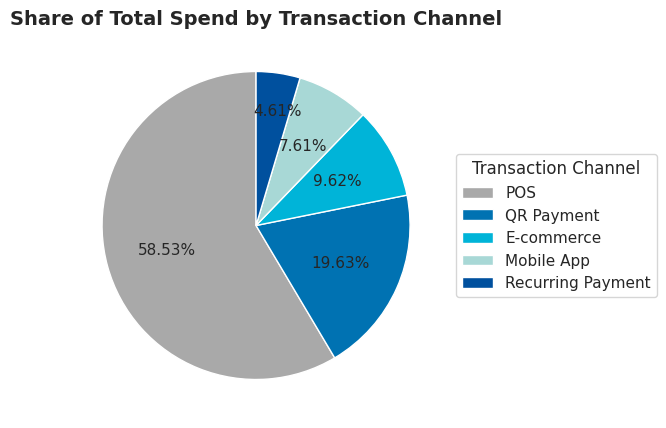

In [34]:
# POS màu xám, các kênh digital tô các sắc xanh
digital_shades = cycle(["#0072B2", "#00B4D8", "#A8D8D6", "#00509E", "#48CAE4", "#90E0EF", "#CAF0F8"])
pie_colors = [
    CHART_GRAY if group == "Offline (POS)" else next(digital_shades)
    for group in channel_stats["group"]
]

fig, ax = plt.subplots()
wedges, texts, autotexts = ax.pie(
    channel_stats["pct_spend"], colors=pie_colors, autopct="%1.2f%%", startangle=90,
)

# Dời nhãn % của lát nhỏ nhất để không đè lên lát bên cạnh
x_pos, y_pos = autotexts[-1].get_position()
autotexts[-1].set_position((x_pos + 0.05, y_pos + 0.15))

ax.set_title("Share of Total Spend by Transaction Channel")
ax.legend(
    wedges, channel_stats["transaction_channel"], title="Transaction Channel",
    loc="center left", bbox_to_anchor=(1, 0, 0.5, 1),
)

save_chart(fig, "task3_channel_spend_share.png")
plt.show()

### 3.3 Category diversity theo nhóm engagement


=== CATEGORY DIVERSITY vs ENGAGEMENT ===
category_diversity: min=2, median=14.0, max=14

Mean category_diversity by engagement segment:
engagement_band
Disengaged             4.62
Moderately Engaged    13.17
Highly Engaged        13.89
Name: category_diversity, dtype: float64


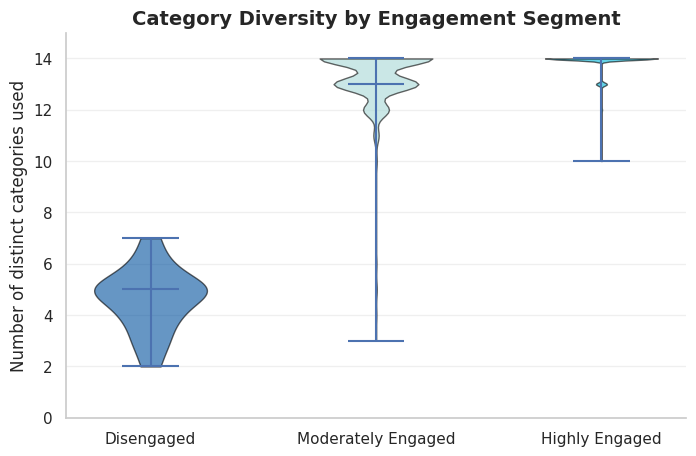

In [35]:
header("CATEGORY DIVERSITY vs ENGAGEMENT")

diversity = cm["category_diversity"]
print(f"category_diversity: min={diversity.min()}, median={diversity.median()}, max={diversity.max()}")
summary["category_diversity_min"] = int(diversity.min())
summary["category_diversity_median"] = float(diversity.median())
summary["category_diversity_max"] = int(diversity.max())

diversity_means = cm.groupby("engagement_band")["category_diversity"].mean().reindex(ENGAGEMENT_BANDS)
print("\nMean category_diversity by engagement segment:")
print(diversity_means.round(2))

fig, ax = plt.subplots()
data_by_band = [cm.loc[cm["engagement_band"] == band, "category_diversity"] for band in ENGAGEMENT_BANDS]
parts = ax.violinplot(data_by_band, showmedians=True, showextrema=True)
for body, band in zip(parts["bodies"], ENGAGEMENT_BANDS):
    body.set_facecolor(ENGAGEMENT_COLORS[band])
    body.set_alpha(0.6)
    body.set_edgecolor("black")
ax.set_xticks(range(1, len(ENGAGEMENT_BANDS) + 1))
ax.set_xticklabels(ENGAGEMENT_BANDS)
ax.set_title("Category Diversity by Engagement Segment")
ax.set_ylabel("Number of distinct categories used")
ax.set_ylim(0, 15)

save_chart(fig, "task3_category_diversity_by_engagement.png")
plt.show()

for band in ENGAGEMENT_BANDS:
    summary[f"category_diversity_mean_{band.replace(' ', '_')}"] = round(float(diversity_means[band]), 2)

### 3.4 Recency và frequency theo nhóm engagement

In [36]:
header("RECENCY & FREQUENCY vs ENGAGEMENT")

recency = cm["transaction_recency_days"]
frequency = cm["transaction_count"]
print(f"transaction_recency_days: min={recency.min()}, median={recency.median()}, max={recency.max()}")
print(f"transaction_count: min={frequency.min()}, median={frequency.median()}, max={frequency.max()}")

summary["recency_min"] = int(recency.min())
summary["recency_median"] = float(recency.median())
summary["recency_max"] = int(recency.max())
summary["frequency_min"] = int(frequency.min())
summary["frequency_median"] = float(frequency.median())
summary["frequency_max"] = int(frequency.max())

recency_means = cm.groupby("engagement_band")["transaction_recency_days"].mean().reindex(ENGAGEMENT_BANDS)
frequency_means = cm.groupby("engagement_band")["transaction_count"].mean().reindex(ENGAGEMENT_BANDS)

print("\nMean recency (days) by engagement segment:")
print(recency_means.round(2))
print("\nMean transactions per month by engagement segment:")
print(frequency_means.round(2))

for band in ENGAGEMENT_BANDS:
    key = band.replace(" ", "_")
    summary[f"recency_mean_{key}"] = round(float(recency_means[band]), 2)
    summary[f"frequency_mean_{key}"] = round(float(frequency_means[band]), 2)


=== RECENCY & FREQUENCY vs ENGAGEMENT ===
transaction_recency_days: min=0, median=0.0, max=30
transaction_count: min=2, median=150.0, max=713

Mean recency (days) by engagement segment:
engagement_band
Disengaged            19.73
Moderately Engaged     0.25
Highly Engaged         0.02
Name: transaction_recency_days, dtype: float64

Mean transactions per month by engagement segment:
engagement_band
Disengaged              9.04
Moderately Engaged     86.96
Highly Engaged        197.65
Name: transaction_count, dtype: float64


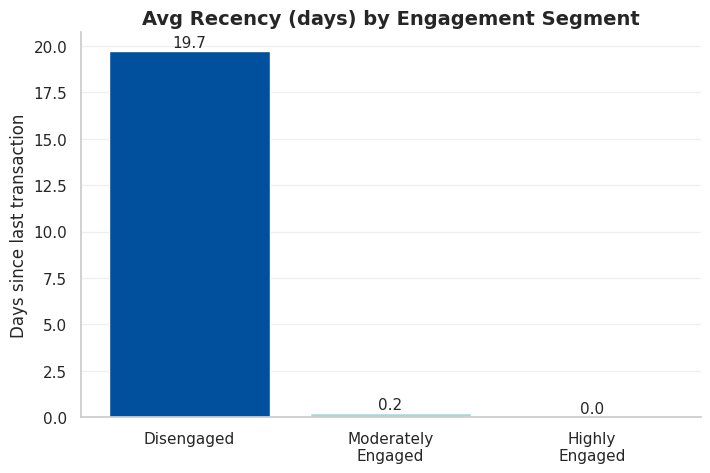

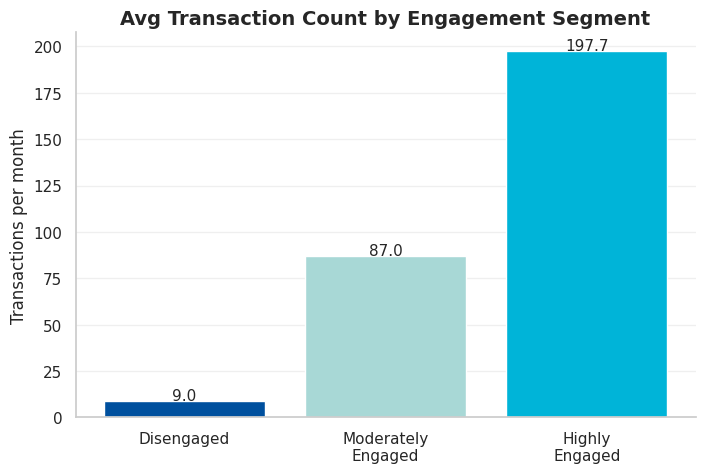

In [37]:
band_labels = [band.replace(" ", "\n") for band in ENGAGEMENT_BANDS]
band_colors = [ENGAGEMENT_COLORS[band] for band in ENGAGEMENT_BANDS]

fig, ax = plt.subplots()
ax.bar(band_labels, recency_means, color=band_colors)
ax.set_title("Avg Recency (days) by Engagement Segment")
ax.set_ylabel("Days since last transaction")
for i, value in enumerate(recency_means):
    ax.text(i, value + 0.2, f"{value:.1f}", ha="center")
save_chart(fig, "task3_recency_by_engagement.png")
plt.show()

fig, ax = plt.subplots()
ax.bar(band_labels, frequency_means, color=band_colors)
ax.set_title("Avg Transaction Count by Engagement Segment")
ax.set_ylabel("Transactions per month")
for i, value in enumerate(frequency_means):
    ax.text(i, value + 0.5, f"{value:.1f}", ha="center")
save_chart(fig, "task3_frequency_by_engagement.png")
plt.show()

### 3.5 Nhóm "Healthy but Disengaged" và phân tích độ nhạy

Ngưỡng tuyệt đối (health ≥ 80 và engagement < 50) cho nhóm rất nhỏ, nên bên dưới thử thêm các bộ ngưỡng khác và ngưỡng tương đối (bottom X% engagement trong nhóm Healthy).

In [38]:
header("HEALTHY BUT DISENGAGED - OFFICIAL THRESHOLD")

n_main = int(cm["healthy_low_eng"].sum())
pct_main = n_main / n_consumer_months * 100
unique_customers_main = cm.loc[cm["healthy_low_eng"], "consumer_id"].nunique()

print(f"Rule: health >= {CROSSOVER_HEALTH_MIN} AND engagement < {CROSSOVER_ENGAGEMENT_MAX}")
print(f"Consumer-months: {n_main:,} ({pct_main:.2f}% of {n_consumer_months:,})")
print(f"Unique customers: {unique_customers_main}")

if n_main < 30:
    print(f"WARNING: n = {n_main} is too small to use as a business target group.")
    print("See the percentile-based tables below for a more usable threshold.")

summary["healthy_disengaged_n"] = n_main
summary["healthy_disengaged_pct"] = round(float(pct_main), 2)
summary["healthy_disengaged_unique_customers"] = int(unique_customers_main)


=== HEALTHY BUT DISENGAGED - OFFICIAL THRESHOLD ===
Rule: health >= 80 AND engagement < 50
Consumer-months: 1 (0.01% of 10,992)
Unique customers: 1
See the percentile-based tables below for a more usable threshold.


In [39]:
# Độ nhạy theo các bộ ngưỡng tuyệt đối (health_min, engagement_max)
sensitivity_thresholds = [(75, 50), (75, 55), (80, 40), (80, 50), (85, 45)]

sensitivity_rows = []
for health_min, engagement_max in sensitivity_thresholds:
    mask = (cm["financial_health_score"] >= health_min) & (cm["engagement_score"] < engagement_max)
    n = int(mask.sum())
    sensitivity_rows.append({
        "health_min": health_min,
        "engagement_max": engagement_max,
        "n_consumer_months": n,
        "pct_of_total": round(n / n_consumer_months * 100, 2),
        "is_official": health_min == CROSSOVER_HEALTH_MIN and engagement_max == CROSSOVER_ENGAGEMENT_MAX,
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
print("Sensitivity analysis (absolute thresholds):")
print(sensitivity_df.to_string(index=False))
save_table(sensitivity_df, "task3_healthy_disengaged_sensitivity.csv")

Sensitivity analysis (absolute thresholds):
 health_min  engagement_max  n_consumer_months  pct_of_total  is_official
         75              50                  7          0.06        False
         75              55                 11          0.10        False
         80              40                  1          0.01        False
         80              50                  1          0.01         True
         85              45                  1          0.01        False


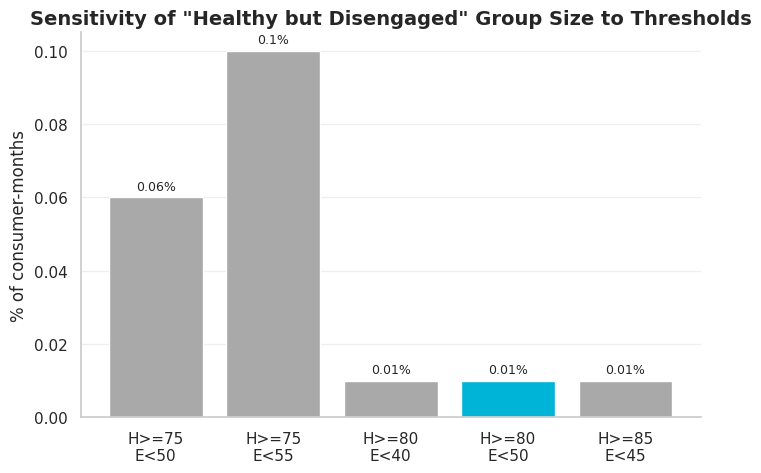

In [40]:
sensitivity_labels = [
    f"H>={row.health_min}\nE<{row.engagement_max}" for row in sensitivity_df.itertuples()
]
sensitivity_colors = [CHART_CYAN if flag else CHART_GRAY for flag in sensitivity_df["is_official"]]

fig, ax = plt.subplots()
bars = ax.bar(sensitivity_labels, sensitivity_df["pct_of_total"], color=sensitivity_colors)
label_offset = sensitivity_df["pct_of_total"].max() * 0.02
for bar, value in zip(bars, sensitivity_df["pct_of_total"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + label_offset, f"{value}%", ha="center", fontsize=9)
ax.set_title('Sensitivity of "Healthy but Disengaged" Group Size to Thresholds')
ax.set_ylabel("% of consumer-months")

save_chart(fig, "task3_healthy_disengaged_sensitivity.png")
plt.show()

In [41]:
# Ngưỡng tương đối: bottom X% engagement trong nhóm Healthy
healthy_mask = cm["financial_health_score"] >= CROSSOVER_HEALTH_MIN
healthy_engagement = cm.loc[healthy_mask, "engagement_score"]
print(f"Consumer-months with health >= {CROSSOVER_HEALTH_MIN}: {int(healthy_mask.sum()):,}")

percentile_rows = []
for p in sorted({10, 15, 20, 25, UNDER_ENGAGED_PERCENTILE}):
    cutoff = float(np.percentile(healthy_engagement, p))
    mask = healthy_mask & (cm["engagement_score"] <= cutoff)
    n = int(mask.sum())
    percentile_rows.append({
        "percentile": f"Bottom {p}%",
        "engagement_cutoff": round(cutoff, 1),
        "n_consumer_months": n,
        "pct_of_total": round(n / n_consumer_months * 100, 2),
        "unique_customers": int(cm.loc[mask, "consumer_id"].nunique()),
    })

percentile_df = pd.DataFrame(percentile_rows)
print("\nSensitivity analysis (percentile within the Healthy group):")
print(percentile_df.to_string(index=False))
save_table(percentile_df, "task3_healthy_disengaged_percentile_sensitivity.csv")

Consumer-months with health >= 80: 475

Sensitivity analysis (percentile within the Healthy group):
percentile  engagement_cutoff  n_consumer_months  pct_of_total  unique_customers
Bottom 10%               65.7                 49          0.45                40
Bottom 15%               66.8                 77          0.70                60
Bottom 20%               68.0                 97          0.88                75
Bottom 25%               69.3                121          1.10                91


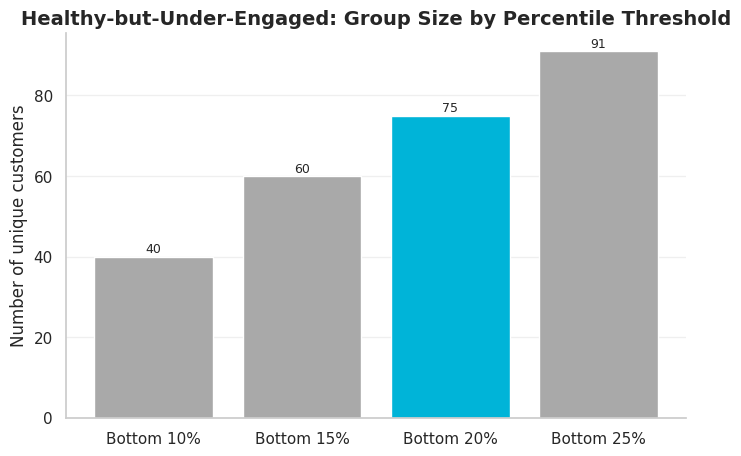

Official group (Bottom 20%): 75 customers / 999 total = 7.51%


In [42]:
# Biểu đồ minh họa cho ngưỡng bottom 20% được chọn làm nhóm chính thức
chosen_label = f"Bottom {UNDER_ENGAGED_PERCENTILE}%"
percentile_colors = [CHART_CYAN if label == chosen_label else CHART_GRAY for label in percentile_df["percentile"]]

fig, ax = plt.subplots()
bars = ax.bar(percentile_df["percentile"], percentile_df["unique_customers"], color=percentile_colors)
for bar, value in zip(bars, percentile_df["unique_customers"]):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 1, f"{value}", ha="center", fontsize=9)
ax.set_title("Healthy-but-Under-Engaged: Group Size by Percentile Threshold")
ax.set_ylabel("Number of unique customers")

save_chart(fig, "task3_healthy_underengaged_percentile_sensitivity.png")
plt.show()

# Tỷ lệ trên tổng khách hàng (không chỉ trên consumer-month)
chosen_row = percentile_df.loc[percentile_df["percentile"] == chosen_label].iloc[0]
pct_of_customer_base = chosen_row["unique_customers"] / n_customers * 100
print(
    f"Official group ({chosen_label}): {int(chosen_row['unique_customers'])} customers "
    f"/ {n_customers:,} total = {pct_of_customer_base:.2f}%"
)

summary["healthy_underengaged_chosen_unique_customers"] = int(chosen_row["unique_customers"])
summary["healthy_underengaged_pct_of_customer_base"] = round(pct_of_customer_base, 2)

In [43]:
# Nhóm "Healthy but Under-Engaged" (bottom 20%) dùng làm đầu vào cho Task 5 (Digital-channel Nudges)
healthy_engagement_cut = float(np.percentile(healthy_engagement, UNDER_ENGAGED_PERCENTILE))
healthy_underengaged_mask = healthy_mask & (cm["engagement_score"] <= healthy_engagement_cut)
healthy_underengaged_ids = set(cm.loc[healthy_underengaged_mask, "consumer_id"])

# Hồ sơ nhân khẩu học của nhóm (nhóm tuyệt đối chỉ có n = 1 nên không dùng để mô tả)
demo_cols = ["occupation", "province_city", "age"]
group_profile = cm.loc[healthy_underengaged_mask, demo_cols]
top_occupations = group_profile["occupation"].value_counts(normalize=True).head(5) * 100
top_provinces = group_profile["province_city"].value_counts(normalize=True).head(5) * 100

print(f"[{chosen_label}, n = {len(group_profile)}] Top 5 occupations (%):")
print(top_occupations.round(1))
print(f"\n[{chosen_label}, n = {len(group_profile)}] Top 5 provinces (%):")
print(top_provinces.round(1))

save_table(
    cm.loc[
        healthy_underengaged_mask,
        ["consumer_id", "analysis_month", "financial_health_score", "engagement_score"],
    ],
    "task3_healthy_underengaged_customer_list.csv",
)

[Bottom 20%, n = 97] Top 5 occupations (%):
occupation
Kỹ sư vật liệu        6.2
Kỹ sư khoan           3.1
Kỹ sư kết cấu         3.1
Kỹ sư đóng tàu        3.1
Giảng viên đại học    3.1
Name: proportion, dtype: float64

[Bottom 20%, n = 97] Top 5 provinces (%):
province_city
Thành phố Hồ Chí Minh    15.5
Đồng Nai                  9.3
Cần Thơ                   8.2
Đồng Tháp                 7.2
Hải Phòng                 6.2
Name: proportion, dtype: float64


### 3.6 Xuất bảng tổng hợp các con số chính

In [44]:
summary_table = pd.Series(summary, name="value").to_frame()
save_table(summary_table, "task3_summary_numbers.csv", index=True)
with open(TABLE_DIR / "task3_summary_numbers.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

header("TASK 3 KEY FIGURES")
print(f"1. Highly Engaged (consumer-months): {summary['engagement_pct_Highly_Engaged']}%")
print(f"2. Disengaged (consumer-months): {summary['engagement_pct_Disengaged']}%")
print(f"3. Average online spend ratio: {summary['avg_online_spend_ratio_pct']}%")
print(f"4. Digital vs Offline spend share: {summary['digital_pct_spend']}% / {summary['offline_pct_spend']}%")
print(
    f"5. Healthy-but-Disengaged (absolute threshold): {summary['healthy_disengaged_unique_customers']} customers | "
    f"Healthy-but-Under-Engaged ({chosen_label}): "
    f"{summary['healthy_underengaged_chosen_unique_customers']} customers "
    f"({summary['healthy_underengaged_pct_of_customer_base']}% of {n_customers:,})"
)


=== TASK 3 KEY FIGURES ===
1. Highly Engaged (consumer-months): 73.99%
2. Disengaged (consumer-months): 0.44%
3. Average online spend ratio: 21.03%
4. Digital vs Offline spend share: 41.47% / 58.54%
5. Healthy-but-Disengaged (absolute threshold): 1 customers | Healthy-but-Under-Engaged (Bottom 20%): 75 customers (7.51% of 999)


### 3.7 Đối chiếu với số liệu đã báo cáo (Task 1 và Task 3)

Các số liệu dưới đây được tính lại trực tiếp từ dữ liệu trong notebook và so với con số đã dùng trong báo cáo / slide. Nếu có dòng lệch, kiểm tra lại dữ liệu nguồn trước khi dùng con số đó.

In [45]:
REPORTED_FIGURES = {
    # Task 1
    "Peak month": (peak_month, 12),
    "Lowest month": (low_month, 2),
    "Peak vs low: spend change (%)": (spend_change, 179.89),
    "Peak vs low: transaction count change (%)": (count_change, 187.33),
    "Peak vs low: average ticket change (%)": (ticket_change, -2.59),
    # Task 2
    "Stressed & Highly Engaged unique customers": (cm.loc[cm["stressed_high_eng"], "consumer_id"].nunique(), 59),
    # Task 3
    "Highly Engaged (% consumer-months)": (summary["engagement_pct_Highly_Engaged"], 73.99),
    "Disengaged (% consumer-months)": (summary["engagement_pct_Disengaged"], 0.44),
    "Average online spend ratio (%)": (summary["avg_online_spend_ratio_pct"], 21.03),
    "Digital spend share (%)": (summary["digital_pct_spend"], 41.47),
    "Offline spend share (%)": (summary["offline_pct_spend"], 58.54),
    "Healthy & Disengaged (official) unique customers": (summary["healthy_disengaged_unique_customers"], 1),
    f"Healthy-under-engaged ({chosen_label}) unique customers": (len(healthy_underengaged_ids), 75),
}

reconciliation = pd.DataFrame(
    [
        {"metric": name, "recomputed": round(float(value), 2), "reported": reported}
        for name, (value, reported) in REPORTED_FIGURES.items()
    ]
)
reconciliation["match"] = np.isclose(
    reconciliation["recomputed"], reconciliation["reported"].astype(float), atol=0.05
)

display(reconciliation)
save_table(reconciliation, "reconciliation_reported_figures.csv")

if reconciliation["match"].all():
    print("All recomputed figures match the reported figures.")
else:
    mismatched = reconciliation.loc[~reconciliation["match"], "metric"].tolist()
    print("WARNING: these figures differ from the reported values:", mismatched)
    print("The source CSV may have changed. Re-check before using them in the report.")

,metric,recomputed,reported,match
0,Peak month,12.00,12.00,True
1,Lowest month,2.00,2.00,True
2,Peak vs low: spend change (%),179.89,179.89,True
3,Peak vs low: transaction count change (%),187.33,187.33,True
4,Peak vs low: average ticket change (%),-2.59,-2.59,True
5,Stressed & Highly Engaged unique customers,59.00,59.00,True
6,Highly Engaged (% consumer-months),73.99,73.99,True
7,Disengaged (% consumer-months),0.44,0.44,True
8,Average online spend ratio (%),21.03,21.03,True
9,Digital spend share (%),41.47,41.47,True


All recomputed figures match the reported figures.


## Task 4 — Customer segmentation

### 4.1 Bảng đặc trưng cấp khách hàng

Gom bảng consumer-month về một dòng / khách hàng: ratio lấy trung bình, số tiền lấy tổng, nhân khẩu học lấy giá trị tháng đầu tiên (coi như cố định trong năm), recency chỉ lấy tháng 12 theo quy tắc chung của nhóm.

In [46]:
MEAN_COLS = [
    "financial_health_score",
    "engagement_score",
    "essential_spend_ratio",
    "discretionary_spend_ratio",
    "online_spend_ratio",
    "spend_to_income_ratio",
    "credit_utilization_ratio",
    "transaction_count",
    "active_transaction_days",
    "category_diversity",
    "spending_volatility",
]
SUM_COLS = [
    "total_spend_vnd",
    "essential_spend_vnd",
    "discretionary_spend_vnd",
    "online_spend_vnd",
]

demo = (
    cm.sort_values("analysis_month")
    .groupby("consumer_id", as_index=False)
    .agg(
        age=("age", "first"),
        gender=("gender", "first"),
        occupation=("occupation", "first"),
        province_city=("province_city", "first"),
        active_months=("analysis_month", "nunique"),
    )
)
means = cm.groupby("consumer_id", as_index=False)[MEAN_COLS].mean()
sums = cm.groupby("consumer_id", as_index=False)[SUM_COLS].sum()
customer = demo.merge(means, on="consumer_id", how="left").merge(sums, on="consumer_id", how="left")

# Khách không có dòng tháng 12 để trống, K-Means sẽ điền bằng median của cột
dec_recency = (
    cm.loc[
        cm["analysis_month"] == pd.Timestamp("2025-12-01"),
        ["consumer_id", "transaction_recency_days"],
    ]
    .rename(columns={"transaction_recency_days": "transaction_recency_days_dec"})
)
customer = customer.merge(dec_recency, on="consumer_id", how="left")

# Số tháng rơi vào hai nhóm giao thoa (cờ đã tạo ở phần Data quality)
flags = (
    cm.groupby("consumer_id")
    .agg(
        stressed_high_eng_months=("stressed_high_eng", "sum"),
        healthy_low_eng_months=("healthy_low_eng", "sum"),
    )
    .reset_index()
)
customer = customer.merge(flags, on="consumer_id", how="left")
customer["stressed_high_eng_share"] = customer["stressed_high_eng_months"] / customer["active_months"]
customer["healthy_low_eng_share"] = customer["healthy_low_eng_months"] / customer["active_months"]

print("Customer-level shape:", customer.shape)
print("Unique customers:", customer["consumer_id"].nunique())
display(customer.head())

Customer-level shape: (999, 26)
Unique customers: 999


,consumer_id,age,gender,occupation,province_city,active_months,financial_health_score,engagement_score,essential_spend_ratio,discretionary_spend_ratio,online_spend_ratio,spend_to_income_ratio,credit_utilization_ratio,transaction_count,active_transaction_days,category_diversity,spending_volatility,total_spend_vnd,essential_spend_vnd,discretionary_spend_vnd,online_spend_vnd,transaction_recency_days_dec,stressed_high_eng_months,healthy_low_eng_months,stressed_high_eng_share,healthy_low_eng_share
0,KH00100010,27,Nam,Kỹ sư sản xuất,Đồng Nai,12,70.616667,78.291667,0.381114,0.618886,0.167251,0.591550,0.155108,243.500000,30.333333,14.000000,0.919464,7036618000,2696137000,4340481000,1180351000,0.0,0,0,0.0,0.0
1,KH00100045,62,Nữ,Chuyên viên sinh lý vận động,Nghệ An,12,68.483333,77.425000,0.476878,0.523122,0.191602,0.624583,0.143142,122.333333,29.416667,13.833333,1.444694,2539338000,1177912000,1361426000,507563000,0.0,0,0,0.0,0.0
2,KH00100050,81,Nữ,Nhà thiết kế dệt may,Cần Thơ,12,60.958333,78.700000,0.504853,0.495147,0.216247,0.792517,0.299525,122.333333,29.666667,13.750000,1.359126,2390488000,1195537000,1194951000,512784000,0.0,0,0,0.0,0.0
3,KH00100085,32,Nữ,Nhà địa vật lý,Thành phố Hồ Chí Minh,12,67.516667,80.441667,0.450735,0.549265,0.219987,0.658675,0.166217,182.333333,30.083333,14.000000,1.290339,4693772000,2098500000,2595272000,1053955000,0.0,0,0,0.0,0.0
4,KH00100090,18,Nam,Kỹ sư hóa học,Tuyên Quang,2,67.850000,49.250000,0.001167,0.998833,0.860883,0.519250,0.161000,6.000000,1.000000,3.500000,0.809247,199844000,288000,199556000,165813000,NaN,0,0,0.0,0.0


### 4.2 Lưu ý về khách hàng không đủ 12 tháng

Không phải khách hàng nào cũng có đủ 12 dòng (ví dụ KH00100090 chỉ tham gia từ tháng 9/2025). Điều này ảnh hưởng đến Task 4 và 5 ở hai điểm:

- Khách không có dòng tháng 12 thì thiếu recency tháng 12, được điền bằng median trong pipeline K-Means.
- Khách có ít tháng lịch sử trông "kém engaged" chỉ vì có ít dữ liệu, chưa chắc thật sự rời bỏ.

Nhóm này **không bị loại** vì Task 4 yêu cầu phủ 100% khách hàng. K-Means sẽ tự tách khách mới / partial-year khỏi khách đủ năm, và điều này được phản ánh khi đặt tên phân khúc ở mục 4.8.

In [47]:
active_months_dist = customer["active_months"].value_counts().sort_index()
print(f"Distribution of active months per customer ({len(customer):,} customers):")
display(active_months_dist)

n_partial = int((customer["active_months"] < 12).sum())
n_missing_dec = int(customer["transaction_recency_days_dec"].isna().sum())
print(f"\nCustomers with < 12 active months: {n_partial} ({100 * n_partial / len(customer):.1f}%)")
print(
    f"Customers missing a December row (recency imputed with median): "
    f"{n_missing_dec} ({100 * n_missing_dec / len(customer):.1f}%)"
)

Distribution of active months per customer (999 customers):


,count
active_months,
1,86
2,5
12,908



Customers with < 12 active months: 91 (9.1%)
Customers missing a December row (recency imputed with median): 81 (8.1%)


### 4.3 Quy mô hai nhóm giao thoa

In [48]:
crossover_summary = pd.DataFrame({
    "Metric": [
        "Stressed & Highly Engaged — monthly records",
        "Stressed & Highly Engaged — unique customers",
        "Healthy & Disengaged — monthly records",
        "Healthy & Disengaged — unique customers",
    ],
    "Value": [
        int(cm["stressed_high_eng"].sum()),
        int(cm.loc[cm["stressed_high_eng"], "consumer_id"].nunique()),
        int(cm["healthy_low_eng"].sum()),
        int(cm.loc[cm["healthy_low_eng"], "consumer_id"].nunique()),
    ],
})

display(crossover_summary)
save_table(crossover_summary, "task4_crossover_summary.csv")

,Metric,Value
0,Stressed & Highly Engaged — monthly records,73
1,Stressed & Highly Engaged — unique customers,59
2,Healthy & Disengaged — monthly records,1
3,Healthy & Disengaged — unique customers,1


### 4.4 Kiểm tra trùng lặp đặc trưng trước khi phân cụm

`financial_health_score` và `engagement_score` vốn được tính từ chính một số cột ratio thô. Nếu đưa cả điểm tổng hợp lẫn các thành phần của nó vào K-Means, một khái niệm sẽ bị tính 2-3 lần trong khoảng cách Euclid và lấn át các chiều chỉ xuất hiện một lần. Vì vậy cần kiểm tra tương quan và PCA trước khi chốt danh sách đặc trưng, thay vì mặc định 9 cột là 9 tín hiệu độc lập.

Kết quả kiểm tra cho thấy `category_diversity` tương quan 0.94 với `engagement_score`, và `spend_to_income_ratio` tương quan -0.88 với `financial_health_score`. Hai cột này bị loại, mỗi khái niệm chỉ giữ một đại diện.

In [49]:
candidate_features = [
    "financial_health_score", "engagement_score", "spend_to_income_ratio",
    "credit_utilization_ratio", "essential_spend_ratio", "online_spend_ratio",
    "category_diversity", "transaction_recency_days_dec", "spending_volatility",
]
REDUNDANCY_THRESHOLD = 0.75  # |r| >= 0.75 coi là hai tín hiệu gần như trùng nhau


def build_preprocessor():
    """Điền median cho giá trị thiếu, rồi chuẩn hóa về cùng thang đo."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])


corr = customer[candidate_features].corr()
print("Correlation matrix (candidate clustering features):")
display(corr.round(2))

print(f"\nPairs with |r| >= {REDUNDANCY_THRESHOLD}:")
for i, feature_a in enumerate(candidate_features):
    for feature_b in candidate_features[i + 1:]:
        r = corr.loc[feature_a, feature_b]
        if abs(r) >= REDUNDANCY_THRESHOLD:
            print(f"  {feature_a} <-> {feature_b}: r = {r:.2f}")

pca = PCA().fit(build_preprocessor().fit_transform(customer[candidate_features]))
print(
    f"\nFirst 2 principal components explain {100 * pca.explained_variance_ratio_[:2].sum():.0f}% "
    f"of the variance across {len(candidate_features)} candidate features"
)

Correlation matrix (candidate clustering features):


,financial_health_score,engagement_score,spend_to_income_ratio,credit_utilization_ratio,essential_spend_ratio,online_spend_ratio,category_diversity,transaction_recency_days_dec,spending_volatility
financial_health_score,1.00,0.02,-0.88,-0.79,0.08,-0.08,0.04,-0.07,-0.13
engagement_score,0.02,1.00,0.11,0.05,0.61,-0.67,0.94,-0.70,0.55
spend_to_income_ratio,-0.88,0.11,1.00,0.72,0.12,-0.13,0.14,-0.01,0.08
credit_utilization_ratio,-0.79,0.05,0.72,1.00,0.07,-0.06,0.07,0.03,0.01
essential_spend_ratio,0.08,0.61,0.12,0.07,1.00,-0.83,0.75,-0.36,0.56
online_spend_ratio,-0.08,-0.67,-0.13,-0.06,-0.83,1.00,-0.86,0.47,-0.49
category_diversity,0.04,0.94,0.14,0.07,0.75,-0.86,1.00,-0.82,0.57
transaction_recency_days_dec,-0.07,-0.70,-0.01,0.03,-0.36,0.47,-0.82,1.00,-0.20
spending_volatility,-0.13,0.55,0.08,0.01,0.56,-0.49,0.57,-0.20,1.00



Pairs with |r| >= 0.75:
  financial_health_score <-> spend_to_income_ratio: r = -0.88
  financial_health_score <-> credit_utilization_ratio: r = -0.79
  engagement_score <-> category_diversity: r = 0.94
  essential_spend_ratio <-> online_spend_ratio: r = -0.83
  online_spend_ratio <-> category_diversity: r = -0.86
  category_diversity <-> transaction_recency_days_dec: r = -0.82

First 2 principal components explain 72% of the variance across 9 candidate features


### 4.5 Chọn số cụm k

Bộ đặc trưng cuối cùng giữ một đại diện cho mỗi khái niệm (đã loại `category_diversity` và `spend_to_income_ratio`). Số cụm k chọn theo silhouette score trong khoảng 3–8.

In [50]:
cluster_features = [
    "financial_health_score",
    "engagement_score",
    "credit_utilization_ratio",
    "essential_spend_ratio",
    "online_spend_ratio",
    "transaction_recency_days_dec",
    "spending_volatility",
]
X = build_preprocessor().fit_transform(customer[cluster_features])

k_results = []
models = {}
for k in K_RANGE:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50)
    labels = model.fit_predict(X)
    k_results.append({
        "k": k,
        "silhouette": silhouette_score(X, labels),
        "inertia": model.inertia_,
    })
    models[k] = model

k_results_df = pd.DataFrame(k_results)
best_k = int(k_results_df.loc[k_results_df["silhouette"].idxmax(), "k"])

print("Selected k =", best_k)
display(k_results_df.round(4))
save_table(k_results_df, "task4_cluster_model_selection.csv")

Selected k = 4


,k,silhouette,inertia
0,3,0.3024,3407.7083
1,4,0.3125,2588.3279
2,5,0.2688,2259.9422
3,6,0.2568,2009.6271
4,7,0.2447,1834.9527
5,8,0.2552,1666.7016


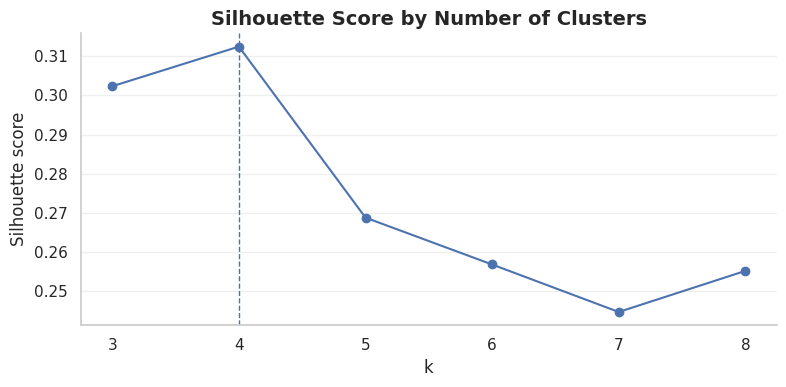

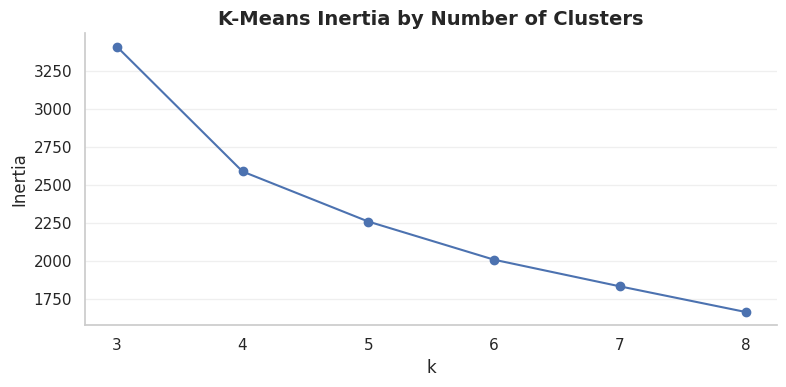

In [51]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_results_df["k"], k_results_df["silhouette"], marker="o")
ax.axvline(best_k, linestyle="--", linewidth=1)
ax.set_title("Silhouette Score by Number of Clusters")
ax.set_xlabel("k")
ax.set_ylabel("Silhouette score")
fig.tight_layout()
save_chart(fig, "task4_01_silhouette_by_k.png")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_results_df["k"], k_results_df["inertia"], marker="o")
ax.set_title("K-Means Inertia by Number of Clusters")
ax.set_xlabel("k")
ax.set_ylabel("Inertia")
fig.tight_layout()
save_chart(fig, "task4_02_inertia_by_k.png")
plt.show()

### 4.6 Mô hình cuối cùng và kiểm tra phủ 100% khách hàng

In [52]:
final_model = models[best_k]
customer["cluster"] = final_model.labels_

coverage_check = {
    "customers_total": len(customer),
    "clustered_customers": customer["cluster"].notna().sum(),
    "unique_clusters": customer["cluster"].nunique(),
    "one_segment_per_customer": customer.groupby("consumer_id")["cluster"].nunique().eq(1).all(),
}
display(pd.DataFrame([coverage_check]))

if (
    not coverage_check["one_segment_per_customer"]
    or coverage_check["clustered_customers"] != coverage_check["customers_total"]
):
    raise AssertionError("Segmentation does not cover exactly 100% of customers.")

,customers_total,clustered_customers,unique_clusters,one_segment_per_customer
0,999,999,4,True


### 4.7 Hồ sơ từng cụm

In [53]:
# Dùng đúng danh sách đặc trưng đã đưa vào K-Means để bảng hồ sơ luôn khớp với mô hình
cluster_profile = customer.groupby("cluster")[cluster_features].mean()
cluster_profile = cluster_profile.join(customer["cluster"].value_counts().sort_index().rename("customers"))
cluster_profile["share_pct"] = 100 * cluster_profile["customers"] / len(customer)

display(cluster_profile.round(3))

,financial_health_score,engagement_score,credit_utilization_ratio,essential_spend_ratio,online_spend_ratio,transaction_recency_days_dec,spending_volatility,customers,share_pct
cluster,,,,,,,,,
0,62.805,77.868,0.240,0.482,0.210,0.012,1.571,416,41.642
1,65.677,49.816,0.172,0.138,0.673,6.800,0.688,84,8.408
2,65.530,38.650,0.199,0.185,0.504,24.400,0.555,5,0.501
3,69.362,78.047,0.152,0.486,0.204,0.008,1.568,494,49.449


### 4.8 Đặt tên phân khúc theo ngữ cảnh kinh doanh

Không dùng dictionary cố định kiểu `{0: "...", 1: "...", ...}`, vì số thứ tự cụm của K-Means là tùy ý và có thể đổi khi chạy trên máy khác, phiên bản sklearn khác hoặc chạy lại. Tên phân khúc được suy ra từ chính thống kê của từng cụm mỗi lần chạy:

1. Tách cụm thành **established** (trung bình ≥ 8/12 tháng có dữ liệu) và **new / partial-year**.
2. Trong nhóm established, xếp theo điểm sức khỏe trung bình: cao nhất → "Financially Healthy & Highly Engaged", thấp nhất → "Financially Stretched but Highly Engaged", các cụm ở giữa → "Stable Active Customers".
3. Trong nhóm new / partial-year, xếp theo recency tháng 12: gần đây nhất → "Emerging Digital Customers", các cụm còn lại → "New & Early-Dormant Customers".

Tên gọi bám theo danh sách phân khúc gợi ý trong đề bài.

In [54]:
cluster_stats = customer.groupby("cluster").agg(
    n=("consumer_id", "size"),
    active_months=("active_months", "mean"),
    health=("financial_health_score", "mean"),
    engagement=("engagement_score", "mean"),
    recency=("transaction_recency_days_dec", "mean"),
)
display(cluster_stats.round(2))

established = cluster_stats[cluster_stats["active_months"] >= ESTABLISHED_MONTHS_THRESHOLD]
established = established.sort_values("health", ascending=False)
partial = cluster_stats[cluster_stats["active_months"] < ESTABLISHED_MONTHS_THRESHOLD]
partial = partial.sort_values("recency", ascending=True)

segment_map = {}
for rank, cluster_id in enumerate(established.index):
    if rank == 0:
        name = "Financially Healthy & Highly Engaged"
    elif rank == len(established) - 1:
        name = "Financially Stretched but Highly Engaged"
    else:
        name = f"Stable Active Customers (tier {rank})"
    segment_map[cluster_id] = name

for rank, cluster_id in enumerate(partial.index):
    segment_map[cluster_id] = "Emerging Digital Customers" if rank == 0 else "New & Early-Dormant Customers"

print("Segment map (cluster id -> business name):")
for cluster_id, name in segment_map.items():
    print(f"  cluster {cluster_id}: {name}")

assert set(segment_map) == set(customer["cluster"].unique()), "Every cluster must receive exactly one business name."
customer["segment"] = customer["cluster"].map(segment_map)

segment_profile = (
    customer.groupby("segment")
    .agg(
        customers=("consumer_id", "size"),
        health=("financial_health_score", "mean"),
        engagement=("engagement_score", "mean"),
        spend_to_income=("spend_to_income_ratio", "mean"),
        credit_utilization=("credit_utilization_ratio", "mean"),
        essential_spend=("essential_spend_ratio", "mean"),
        online_spend=("online_spend_ratio", "mean"),
        category_diversity=("category_diversity", "mean"),
        recency_dec=("transaction_recency_days_dec", "mean"),
        spending_volatility=("spending_volatility", "mean"),
        stressed_high_eng_customers=("stressed_high_eng_months", lambda s: (s > 0).sum()),
        healthy_low_eng_customers=("healthy_low_eng_months", lambda s: (s > 0).sum()),
    )
    .reset_index()
)
segment_profile["share_pct"] = 100 * segment_profile["customers"] / len(customer)
segment_profile = segment_profile.sort_values("customers", ascending=False)

display(segment_profile.round(3))

,n,active_months,health,engagement,recency
cluster,,,,,
0,416,11.97,62.81,77.87,0.01
1,84,1.05,65.68,49.82,6.80
2,5,1.20,65.53,38.65,24.40
3,494,11.98,69.36,78.05,0.01


Segment map (cluster id -> business name):
  cluster 3: Financially Healthy & Highly Engaged
  cluster 0: Financially Stretched but Highly Engaged
  cluster 1: Emerging Digital Customers
  cluster 2: New & Early-Dormant Customers


,segment,customers,health,engagement,spend_to_income,credit_utilization,essential_spend,online_spend,category_diversity,recency_dec,spending_volatility,stressed_high_eng_customers,healthy_low_eng_customers,share_pct
1,Financially Healthy & Highly Engaged,494,69.362,78.047,0.605,0.152,0.486,0.204,13.741,0.008,1.568,5,0,49.449
2,Financially Stretched but Highly Engaged,416,62.805,77.868,0.814,0.240,0.482,0.210,13.688,0.012,1.571,54,0,41.642
0,Emerging Digital Customers,84,65.677,49.816,0.615,0.172,0.138,0.673,5.018,6.800,0.688,0,1,8.408
3,New & Early-Dormant Customers,5,65.530,38.650,0.629,0.199,0.185,0.504,4.000,24.400,0.555,0,0,0.501


### 4.9 Biểu đồ quy mô và hồ sơ chuẩn hóa của các phân khúc

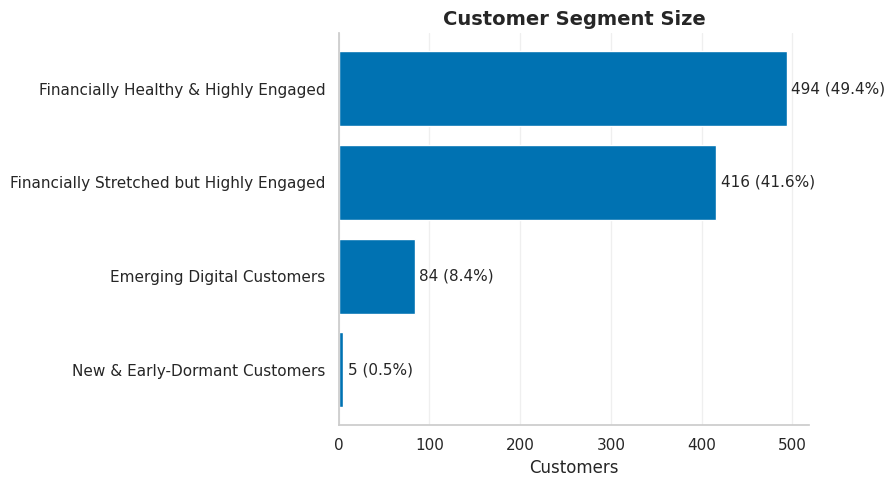

In [55]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(segment_profile["segment"], segment_profile["customers"], color=CHART_BLUE)
ax.invert_yaxis()
ax.set_title("Customer Segment Size")
ax.set_xlabel("Customers")
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
for i, value in enumerate(segment_profile["customers"]):
    ax.text(value + 5, i, f"{value} ({value / len(customer):.1%})", va="center")

fig.tight_layout()
save_chart(fig, "task4_03_segment_size.png")
plt.show()

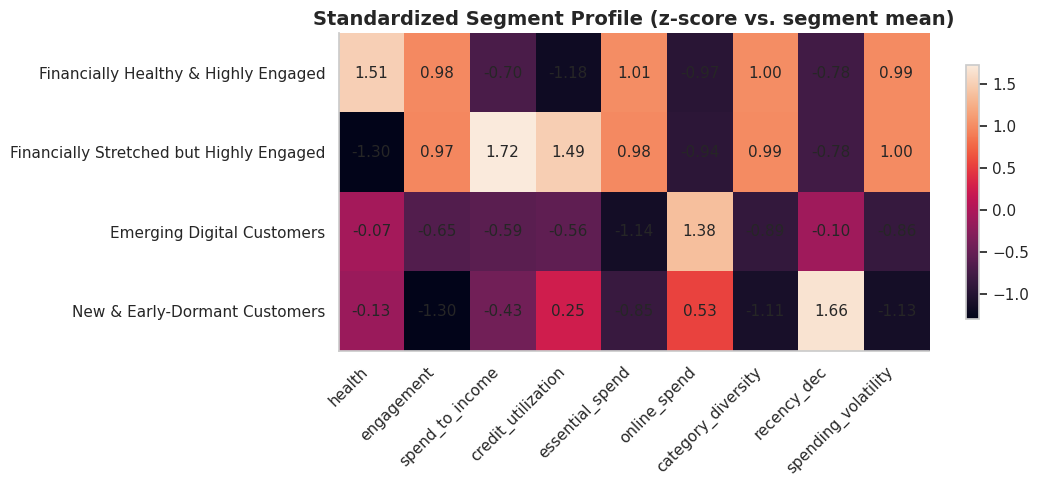

In [56]:
heat_cols = [
    "health", "engagement", "spend_to_income", "credit_utilization", "essential_spend",
    "online_spend", "category_diversity", "recency_dec", "spending_volatility",
]
heat = segment_profile.set_index("segment")[heat_cols]
heat_z = (heat - heat.mean()) / heat.std(ddof=0)  # z-score của từng chỉ số giữa các phân khúc

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(heat_z.values, aspect="auto")
ax.grid(False)
ax.set_title("Standardized Segment Profile (z-score vs. segment mean)")
ax.set_yticks(range(len(heat_z.index)))
ax.set_yticklabels(heat_z.index)
ax.set_xticks(range(len(heat_z.columns)))
ax.set_xticklabels(heat_z.columns, rotation=45, ha="right")
for i in range(heat_z.shape[0]):
    for j in range(heat_z.shape[1]):
        ax.text(j, i, f"{heat_z.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, shrink=0.8)

fig.tight_layout()
save_chart(fig, "task4_04_segment_profile_heatmap.png")
plt.show()

### 4.10 Kiểm chứng: ma trận 2x2 theo luật so với cụm K-Means

Dàn ý của đề bài gợi ý dựng trước một ma trận 2x2 đơn giản (health x engagement, chia theo median) làm baseline, rồi dùng K-Means để kiểm tra xem có tìm ra cùng cấu trúc hay không. Đây là bước kiểm chứng, không thay thế các phân khúc K-Means ở trên.

Nếu bảng chéo cho thấy các cụm bám khá sát các ô của ma trận 2x2, nghĩa là K-Means khôi phục được cấu trúc chung của luật đơn giản, đồng thời bổ sung các phân biệt chi tiết hơn (khách mới / partial-year, credit utilization, ...).

In [57]:
health_median = customer["financial_health_score"].median()
engagement_median = customer["engagement_score"].median()
high_health = customer["financial_health_score"] >= health_median
high_engagement = customer["engagement_score"] >= engagement_median

customer["rule_based_quadrant"] = np.select(
    [high_health & high_engagement, high_health & ~high_engagement, ~high_health & high_engagement],
    ["Healthy & Engaged", "Healthy & Disengaged", "Stretched & Engaged"],
    default="Stretched & Disengaged",
)

validation_crosstab = pd.crosstab(customer["segment"], customer["rule_based_quadrant"])
print(f"Median health = {health_median:.2f} | median engagement = {engagement_median:.2f}")
print("Rows: K-Means segment | Columns: median-split 2x2 quadrant")
display(validation_crosstab)
save_table(validation_crosstab, "task4_validation_2x2_vs_kmeans.csv", index=True)

Median health = 66.24 | median engagement = 78.17
Rows: K-Means segment | Columns: median-split 2x2 quadrant


rule_based_quadrant,Healthy & Disengaged,Healthy & Engaged,Stretched & Disengaged,Stretched & Engaged
segment,,,,
Emerging Digital Customers,37,0,47,0
Financially Healthy & Highly Engaged,195,230,25,44
Financially Stretched but Highly Engaged,24,13,163,216
New & Early-Dormant Customers,2,0,3,0


## Task 5 — Recommendations

### 5.1 Luật chọn tệp khách hàng cho từng can thiệp

Lưu ý khi đọc kết quả:

- **Reach gần 25% là do thiết kế.** Ba trong sáu luật dùng ngưỡng quantile 0.75 hoặc 0.25 trên một đặc trưng, nên reach của chúng gần 25% của 999 khách hàng theo định nghĩa của quantile. Đây không phải ba phát hiện độc lập tình cờ trùng số, và nên nói rõ điều này trên slide.
- **Driver strength phải đo trên chỉ số khác với chỉ số dùng để chọn nhóm.** Nhóm được chọn bằng "top quartile của chính chỉ số X" thì luôn có effect size (Cohen's d) rất lớn trên X, nên đó là phép đo vòng tròn, không có ý nghĩa. Vì vậy mỗi luật có thêm một `evidence_metric` không tham gia vào việc chọn nhóm, và câu hỏi thực sự là: nhóm này có khác biệt trên một tín hiệu độc lập hay không?
- **Digital-channel Nudges** dùng nhóm Healthy-under-engaged (bottom 20%) của Task 3, không dùng luật tuyệt đối (health ≥ 80 và engagement < 50, chỉ có 1 khách), để nhóm mục tiêu không bị thay bằng đúng 1 khách hàng.

In [58]:
q25_health = customer["financial_health_score"].quantile(0.25)
q75_health = customer["financial_health_score"].quantile(0.75)
q75_sti = customer["spend_to_income_ratio"].quantile(0.75)
q75_vol = customer["spending_volatility"].quantile(0.75)
q75_essential = customer["essential_spend_ratio"].quantile(0.75)
q75_engagement = customer["engagement_score"].quantile(0.75)
median_sti = customer["spend_to_income_ratio"].median()

# recommendation_rules[action] = (mask, defining_metric, evidence_metric, rule_text)
#   defining_metric: đặc trưng dùng để dựng mask (giữ lại để truy vết)
#   evidence_metric: đặc trưng khác, chỉ dùng để đo driver strength (Cohen's d)
recommendation_rules = {
    "Budgeting Tool": (
        customer["spend_to_income_ratio"] >= q75_sti,
        "spend_to_income_ratio",
        "credit_utilization_ratio",
        f"Spend-to-income ratio >= {q75_sti:.4f}",
    ),
    "Spend Alerts": (
        customer["spending_volatility"] >= q75_vol,
        "spending_volatility",
        "financial_health_score",
        f"Spending volatility >= {q75_vol:.4f}",
    ),
    "Financial-planning Reminders": (
        customer["financial_health_score"] <= q25_health,
        "financial_health_score",
        "spend_to_income_ratio",
        f"Financial health score <= {q25_health:.2f}",
    ),
    "Financial Education": (
        (customer["essential_spend_ratio"] >= q75_essential)
        & (customer["spend_to_income_ratio"] >= median_sti),
        "essential_spend_ratio",
        "credit_utilization_ratio",
        f"Essential-spend ratio >= {q75_essential:.4f} AND spend-to-income >= median {median_sti:.4f}",
    ),
    "Digital-channel Nudges": (
        customer["consumer_id"].isin(healthy_underengaged_ids),
        "engagement_score",
        "online_spend_ratio",
        f"Healthy customers in bottom {UNDER_ENGAGED_PERCENTILE}% of engagement; cutoff = {healthy_engagement_cut:.2f}",
    ),
    "Product Suggestions": (
        (customer["financial_health_score"] >= q75_health)
        & (customer["engagement_score"] >= q75_engagement),
        "financial_health_score",
        "total_spend_vnd",
        f"Health >= {q75_health:.2f} AND engagement >= {q75_engagement:.2f}",
    ),
}


def cohens_d(mask, metric):
    """Effect size (giá trị tuyệt đối) của `metric` giữa nhóm được chọn và phần còn lại."""
    a = customer.loc[mask, metric].astype(float)
    b = customer.loc[~mask, metric].astype(float)
    if len(a) < 2 or len(b) < 2:
        return np.nan
    pooled = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return abs((a.mean() - b.mean()) / pooled) if pooled != 0 else np.nan


actions = []
for action, (mask, defining_metric, evidence_metric, rule_text) in recommendation_rules.items():
    actions.append({
        "action": action,
        "rule": rule_text,
        "defining_metric": defining_metric,
        "evidence_metric": evidence_metric,
        "reach_customers": int(mask.sum()),
        "reach_pct": 100 * mask.mean(),
        # Vòng tròn theo thiết kế: chỉ để đối chiếu, không dùng để xếp hạng
        "driver_strength_on_defining_metric": cohens_d(mask, defining_metric),
        # Bằng chứng thực sự: nhóm có khác biệt trên chỉ số không tham gia chọn nhóm
        "driver_strength_on_evidence_metric": cohens_d(mask, evidence_metric),
    })

recommendations = pd.DataFrame(actions)
recommendations["reach_rank"] = recommendations["reach_customers"].rank(method="dense", ascending=False).astype(int)
# na_option="bottom": nhóm rỗng hoặc chỉ có 1 khách (Cohen's d = NaN) xếp cuối thay vì làm lỗi astype(int)
recommendations["driver_strength_rank"] = (
    recommendations["driver_strength_on_evidence_metric"]
    .rank(method="dense", ascending=False, na_option="bottom")
    .astype(int)
)
recommendations = recommendations.sort_values(
    ["reach_customers", "driver_strength_on_evidence_metric"], ascending=[False, False]
)

display(recommendations.round(4))

,action,rule,defining_metric,evidence_metric,reach_customers,reach_pct,driver_strength_on_defining_metric,driver_strength_on_evidence_metric,reach_rank,driver_strength_rank
2,Financial-planning Reminders,Financial health score <= 63.40,financial_health_score,spend_to_income_ratio,250,25.0250,2.3824,1.8516,1,1
0,Budgeting Tool,Spend-to-income ratio >= 0.7930,spend_to_income_ratio,credit_utilization_ratio,250,25.0250,2.5134,1.3952,1,2
1,Spend Alerts,Spending volatility >= 1.7691,spending_volatility,financial_health_score,250,25.0250,2.5051,0.3473,1,6
3,Financial Education,Essential-spend ratio >= 0.5257 AND spend-to-i...,essential_spend_ratio,credit_utilization_ratio,123,12.3123,0.9325,0.7570,2,4
4,Digital-channel Nudges,Healthy customers in bottom 20% of engagement;...,engagement_score,online_spend_ratio,75,7.5075,0.2843,0.3897,3,5
5,Product Suggestions,Health >= 69.28 AND engagement >= 79.92,financial_health_score,total_spend_vnd,62,6.2062,1.3158,1.1265,4,3


Dùng `driver_strength_on_evidence_metric` cho Impact Prioritization Matrix (slide 20). Cột `driver_strength_on_defining_metric` chỉ để đối chiếu và lớn theo thiết kế.

### 5.2 Xuất danh sách khách hàng mục tiêu và các bảng tổng hợp

In [59]:
target_rows = []
for action, (mask, _, _, _) in recommendation_rules.items():
    targets = customer.loc[
        mask,
        [
            "consumer_id", "segment", "province_city", "age", "financial_health_score",
            "engagement_score", "spend_to_income_ratio", "credit_utilization_ratio",
            "essential_spend_ratio", "online_spend_ratio",
        ],
    ].copy()
    targets.insert(0, "action", action)
    target_rows.append(targets)

recommendation_targets = pd.concat(target_rows, ignore_index=True)

save_table(customer, "task4_customer_level_segmentation.csv")
save_table(segment_profile, "task4_segment_profiles.csv")
save_table(recommendations, "task5_recommendation_actions.csv")
save_table(recommendation_targets, "task5_recommendation_target_customers.csv")

print(f"Exported {len(recommendation_targets):,} target rows across {len(recommendation_rules)} actions.")

Exported 1,010 target rows across 6 actions.


### 5.3 Biểu đồ reach của các can thiệp

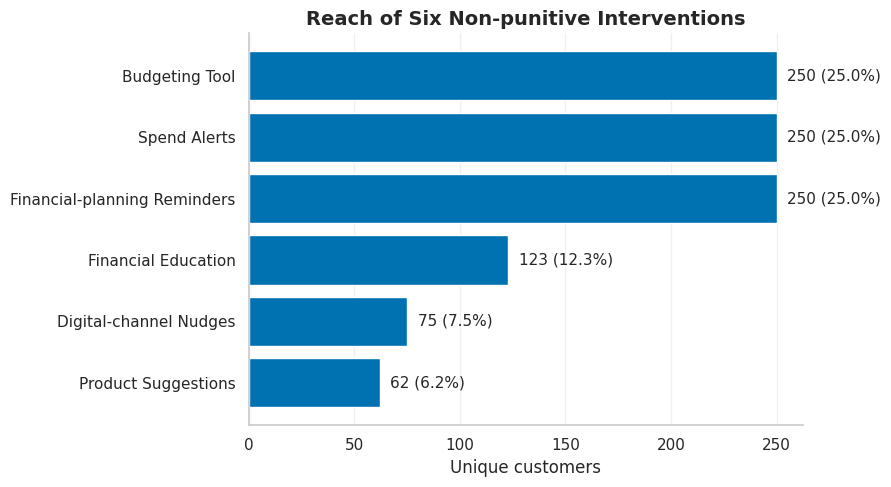

In [60]:
plot_rec = recommendations.sort_values("reach_customers", ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_rec["action"], plot_rec["reach_customers"], color=CHART_BLUE)
ax.set_title("Reach of Six Non-punitive Interventions")
ax.set_xlabel("Unique customers")
ax.grid(axis="x", alpha=0.3)
ax.grid(axis="y", visible=False)
for i, row in plot_rec.iterrows():
    ax.text(row["reach_customers"] + 5, i, f"{int(row['reach_customers'])} ({row['reach_pct']:.1f}%)", va="center")

fig.tight_layout()
save_chart(fig, "task5_01_recommendation_reach.png")
plt.show()

## Limitations & future work

In [61]:
limitations = [
    "Segmentation runs on customer-level *averages* of monthly ratios (Jan-Dec 2025). "
    "This smooths out month-to-month volatility, so a customer who was briefly stressed "
    "in one month but healthy the rest of the year is not flagged as 'stressed' at this grain.",

    f"{n_partial} customers ({100 * n_partial / len(customer):.1f}%) have fewer than 12 months "
    "of history (e.g. joined mid-year). K-Means correctly isolated most of them into their "
    "own cluster(s) rather than forcing them into the two established-customer segments, "
    "but their profiles are based on very few data points and should be treated as provisional.",

    f"December transaction recency was missing for {n_missing_dec} customers and was "
    "imputed with the feature's median before scaling/clustering. This is a reasonable "
    "default but slightly compresses the true spread of the recency feature.",

    "All synthetic financial fields (income, credit limit, balances) are inflated relative "
    "to real Vietnamese salaries by construction (see case study, Section 7/12). Only "
    "ratio-based features were used for clustering and recommendation rules for this reason; "
    "no raw VND figures were used as clustering inputs or thresholds.",

    "financial_health_score is a wellbeing indicator, not a credit score. No output of this "
    "notebook is used, or should ever be used, to approve, deny, or reprice credit.",

    "K-means with k chosen by silhouette score is one reasonable segmentation method; the "
    "silhouette scores in Section 4.5 show a shallow, not razor-sharp, peak at k="
    f"{best_k} (see the model-selection chart), so alternative k or algorithms (e.g. "
    "Gaussian mixtures, hierarchical clustering) could reasonably produce a different but "
    "still defensible split.",

    "Segment names are derived programmatically from cluster statistics (Section 4.8) rather "
    "than hand-picked, which improves reproducibility, but the underlying business meaning "
    "should still be sanity-checked by a human against a few example customers before it "
    "goes on a client-facing slide.",

    "Task 5 driver strength is scored on a separate, non-defining 'evidence_metric' "
    "rather than on the feature used to build the target-group mask itself (e.g. "
    "Budgeting Tool is defined by spend-to-income but its evidence metric is "
    "credit_utilization_ratio). Scoring effect size on the same feature used to define "
    "the group would be circular -- a group defined as its own top quartile always shows "
    "a large, uninformative effect size on that feature. That same-feature number is "
    "still reported in the output table for audit purposes but is not used for ranking.",

    "Clustering features were checked for redundancy first (Section 4.4): category_diversity "
    "and spend_to_income_ratio were dropped because they were near-duplicates (|r| >= 0.75) "
    "of engagement_score / financial_health_score. credit_utilization_ratio was kept despite "
    "a residual r = -0.79 with financial_health_score, since credit-line usage intensity is a "
    "meaningfully different lever for the business (a spend-alert/product-suggestion decision) "
    "than the composite health score itself; this residual correlation still means the "
    "'financial stress' construct carries somewhat more implicit weight in the clustering "
    "distance than a single, fully independent feature would.",
]

future_work = [
    "Re-run clustering on month-level (not averaged) features, or add trend features "
    "(e.g. health-score slope over the year), to catch customers whose situation is "
    "changing rather than stable.",

    "Cross-validate segment stability by re-fitting K-Means on a bootstrap resample of "
    "customers and checking that segment membership and sizes stay broadly consistent.",

    "Feed the six Task 5 intervention target lists into the (optional) "
    "next_month_low_health_flag model, using a chronological train/validation/test split, "
    "to prioritize outreach toward customers about to cross into a lower health segment.",

    "Once real (non-synthetic) data is available, re-derive every quantile-based threshold "
    "in Task 5 (Section 5.1) instead of reusing the ones calibrated on synthetic data.",
]

header("LIMITATIONS")
for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}\n")

header("FUTURE WORK")
for i, item in enumerate(future_work, 1):
    print(f"{i}. {item}\n")

save_table(pd.DataFrame({"limitations": limitations}), "task4_limitations.csv")
save_table(pd.DataFrame({"future_work": future_work}), "task4_future_work.csv")


=== LIMITATIONS ===
1. Segmentation runs on customer-level *averages* of monthly ratios (Jan-Dec 2025). This smooths out month-to-month volatility, so a customer who was briefly stressed in one month but healthy the rest of the year is not flagged as 'stressed' at this grain.

2. 91 customers (9.1%) have fewer than 12 months of history (e.g. joined mid-year). K-Means correctly isolated most of them into their own cluster(s) rather than forcing them into the two established-customer segments, but their profiles are based on very few data points and should be treated as provisional.

3. December transaction recency was missing for 81 customers and was imputed with the feature's median before scaling/clustering. This is a reasonable default but slightly compresses the true spread of the recency feature.

4. All synthetic financial fields (income, credit limit, balances) are inflated relative to real Vietnamese salaries by construction (see case study, Section 7/12). Only ratio-based feat

## Output files

Toàn bộ kết quả của notebook nằm trong `outputs/`.

In [62]:
for folder in (CHART_DIR, TABLE_DIR):
    files = sorted(path.name for path in folder.iterdir())
    print(f"{folder}/  ({len(files)} files)")
    for name in files:
        print("  -", name)

outputs/charts/  (22 files)
  - task1_q1_monthly_spending.png
  - task1_q2_spending_allocation.png
  - task1_q3_channel_breakdown.png
  - task1_q4_category_comparison.png
  - task1_q5_age_cohort.png
  - task2_1_health_segments.png
  - task2_2_health_drivers.png
  - task2_3_demographics.png
  - task2_4_stressed_highly_engaged.png
  - task3_category_diversity_by_engagement.png
  - task3_channel_spend_share.png
  - task3_engagement_distribution_hist.png
  - task3_engagement_segment_share.png
  - task3_frequency_by_engagement.png
  - task3_healthy_disengaged_sensitivity.png
  - task3_healthy_underengaged_percentile_sensitivity.png
  - task3_recency_by_engagement.png
  - task4_01_silhouette_by_k.png
  - task4_02_inertia_by_k.png
  - task4_03_segment_size.png
  - task4_04_segment_profile_heatmap.png
  - task5_01_recommendation_reach.png
outputs/tables/  (27 files)
  - reconciliation_reported_figures.csv
  - task1_q1_monthly_spending.csv
  - task1_q2_spending_mix_by_health.csv
  - task1_q3_ch

In [63]:
!zip -r /content/outputs.zip /content/outputs

  adding: content/outputs/ (stored 0%)
  adding: content/outputs/tables/ (stored 0%)
  adding: content/outputs/tables/task3_summary_numbers.json (deflated 70%)
  adding: content/outputs/tables/task4_limitations.csv (deflated 51%)
  adding: content/outputs/tables/task2_1_health_segments.csv (deflated 12%)
  adding: content/outputs/tables/task5_recommendation_target_customers.csv (deflated 76%)
  adding: content/outputs/tables/task1_q3_province_digital_adoption.csv (deflated 44%)
  adding: content/outputs/tables/task3_healthy_disengaged_sensitivity.csv (deflated 32%)
  adding: content/outputs/tables/task1_q5_age_cohort_summary.csv (deflated 33%)
  adding: content/outputs/tables/task4_future_work.csv (deflated 41%)
  adding: content/outputs/tables/task1_q1_monthly_spending.csv (deflated 45%)
  adding: content/outputs/tables/task3_healthy_disengaged_percentile_sensitivity.csv (deflated 29%)
  adding: content/outputs/tables/reconciliation_reported_figures.csv (deflated 52%)
  adding: conten

In [64]:
from google.colab import files
files.download('/content/outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>